# Week 3 ? Matplotlib, Seaborn and diagnosis

Official brief: [Week 3 assignments](https://github.com/UsmarHaider/data-visualization/blob/main/week3/assignments/TASKS.md). Course overview: [Week 3 README](https://github.com/UsmarHaider/data-visualization/blob/main/week3/README.md); data dictionary: `assignments/data/DATA_DICTIONARY.md`. All case data are synthetic.

This reproducible notebook rebuilds the nine assigned cases (cases 4 and 5 retain the brief?s required statistics tables), computes Lie Factors through the official toolkit, tests palette simulations, and creates the 300-dpi clinical figure and one-page justification. The clinical scenarios are not real patients.

In [1]:
from pathlib import Path
import sys
sys.path.insert(0, 'assignments')
from IPython.display import display, Image
import pandas as pd
import week3_partA, week3_partBC, week3_partD
chart_dir = Path('charts')

## Part A ? rebuild and diagnose

Mechanisms use the actual data: road-type confounding in the helmet comparison, enrollment/exam exposure in chai/fail counts, industrial-monitor attrition in AQI, shape information loss in equal-moment tables, signed-correlation encoding, dual axes, bin-width sensitivity, and KDE spillover at the SpO? ceiling. Cases 4 and 5 are tables in the official recipe; scatter panels are diagnostic exhibits, not replacements for those tables.

Week 3 Part A: rebuilt cases and exported diagnoses, statistics tables and 9-page PDF. Cases 4/5 retain the official table deliverable plus scatter exhibits.


,case,claim,first_objection,mechanism,redesign
0,1,Premium-certified helmets have 2.5x the head-i...,The prescribed zero-baseline bars reproduce 2....,Road-type exposure confounds the pooled rates:...,Stratify by road type; pooled rates do not sho...
1,2,Canteen chai sales predict quiz failures,The fitted line is faithful to the recipe and ...,Exposure/time trend: cups correlate with enrol...,Compare exposure-normalized failure rates by e...
2,3,Smog Action Plan cut Lahore AQI by a third,Zero baseline is honored; means are 202 versus...,Coverage falls from 22 to 13 reporting station...,Show zone means and a fixed-station panel (n=1...
3,4,"Four departments behave identically, so fund t...",The repeated moments are deliberately construc...,"Equal n=11, means 18/14.5 and r≈.816 do not im...",Keep the required summary table and inspect th...
4,5,"Five cohorts, one set of statistics",The repeated moments are deliberately construc...,"Each n=180 group has mean 48/63, SD 12/15 and ...",Keep the required summary table and inspect th...
5,6,Creatinine tracks HbA1c — a finding,The matrix is 20×20 and the pair is r=.765; sa...,Two defects: sequential Reds has no neutral mi...,Use a diverging map fixed −1…+1 and mask one t...
6,7,ShaheenGo ran at a loss until May,"Both series share PKR millions, so separate sc...",Independent y-axis transformations make visual...,Use a common zero-based axis and direct margin...
7,8,"Three bin widths, three different distributions","Every panel uses the same n=10,000 values; sam...",Binning is a display parameter: 3 bins hide de...,Use the explicit Freedman–Diaconis rule (29 bi...
8,9,4.4% of the density sits above 100% saturation,Observed maximum is exactly 100; no record exc...,Gaussian KDE convolves discrete bounded observ...,Use the empirical integer distribution or a bo...


,group,n,mean_x,mean_y,sd_x,sd_y,pearson_r,regression_slope
0,Architecture,11,18.0,14.500909,6.63325,2.030579,0.816521,0.249955
1,Business Administration,11,18.0,14.500909,6.63325,2.031657,0.816237,0.250000
2,Computer Science,11,18.0,14.500909,6.63325,2.031568,0.816421,0.250045
3,Electrical Engineering,11,18.0,14.500000,6.63325,2.030424,0.816287,0.249864


,group,n,mean_x,mean_y,sd_x,sd_y,pearson_r,regression_slope
0,ring,180,48.000017,62.999994,12.033475,15.041840,0.420003,0.525004
1,star,180,47.999978,62.999989,12.033468,15.041871,0.419998,0.524998
2,straight line,180,48.000000,63.000006,12.033496,15.041835,0.419999,0.524998
3,the letter X,180,48.000000,62.999989,12.033429,15.041823,0.419999,0.524999
4,two clusters,180,48.000022,63.000017,12.033480,15.041843,0.419997,0.524996


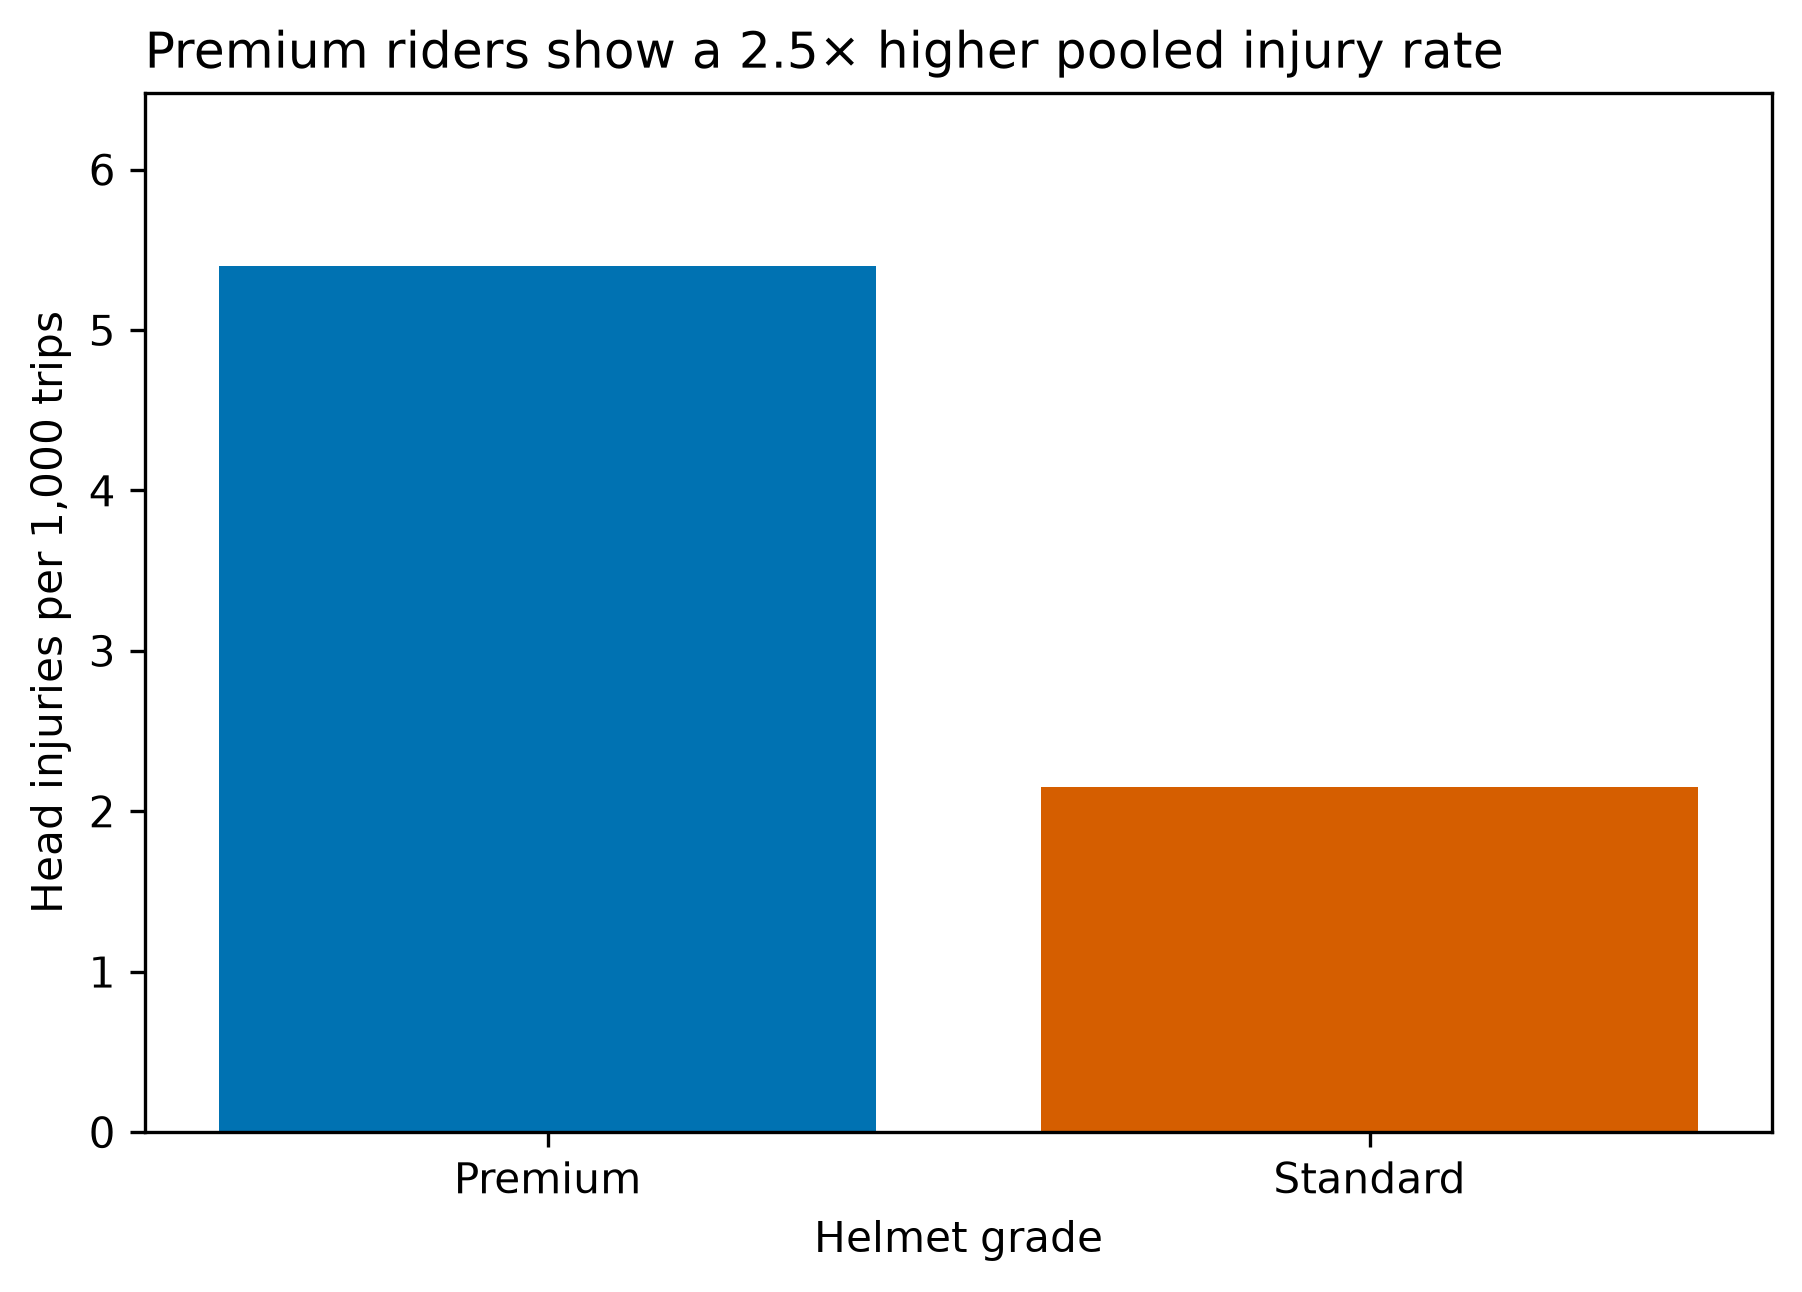

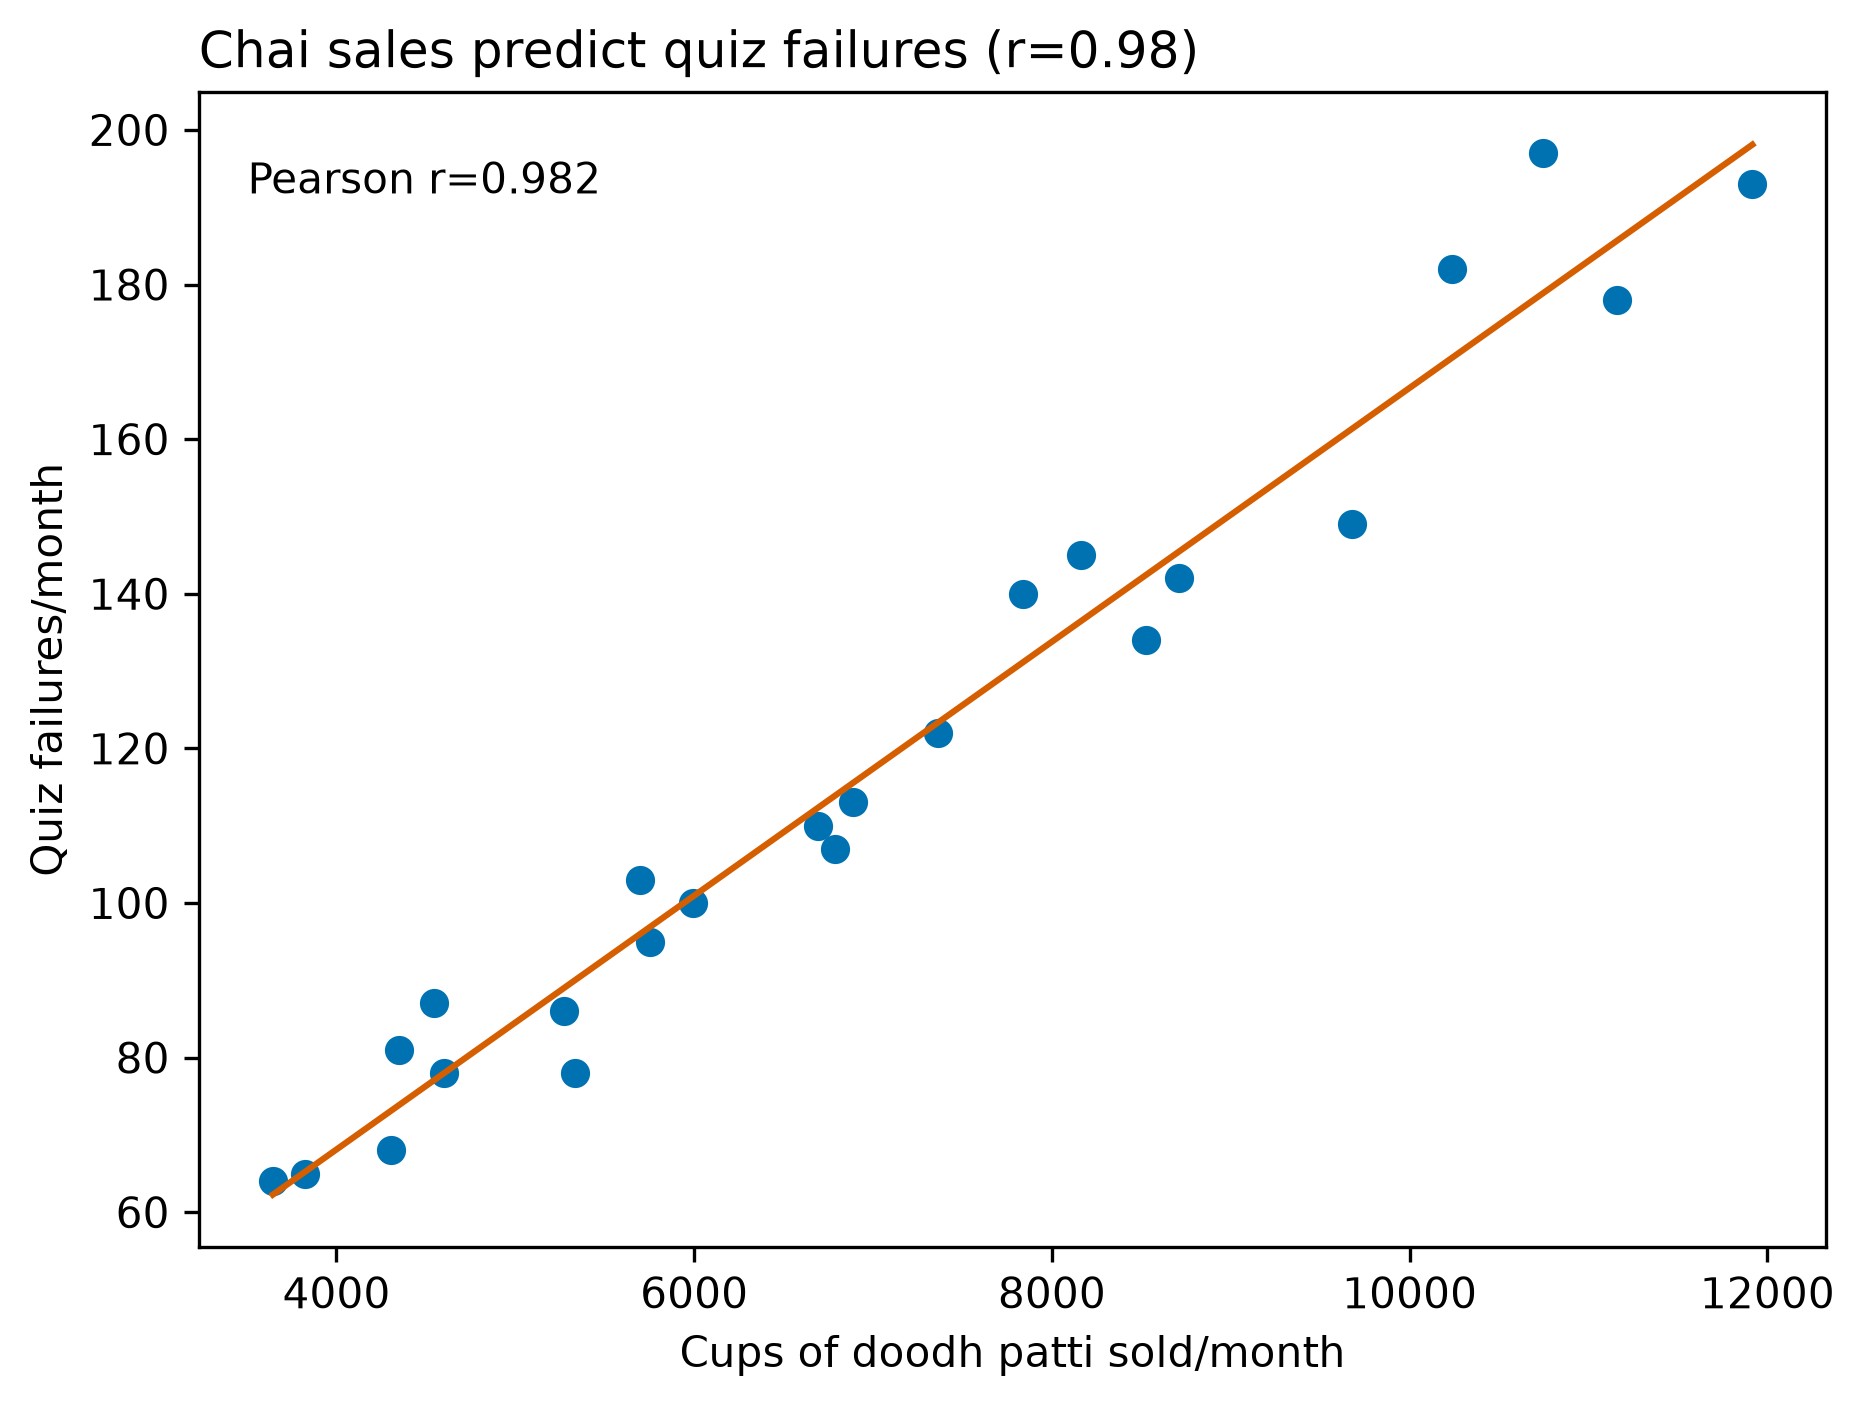

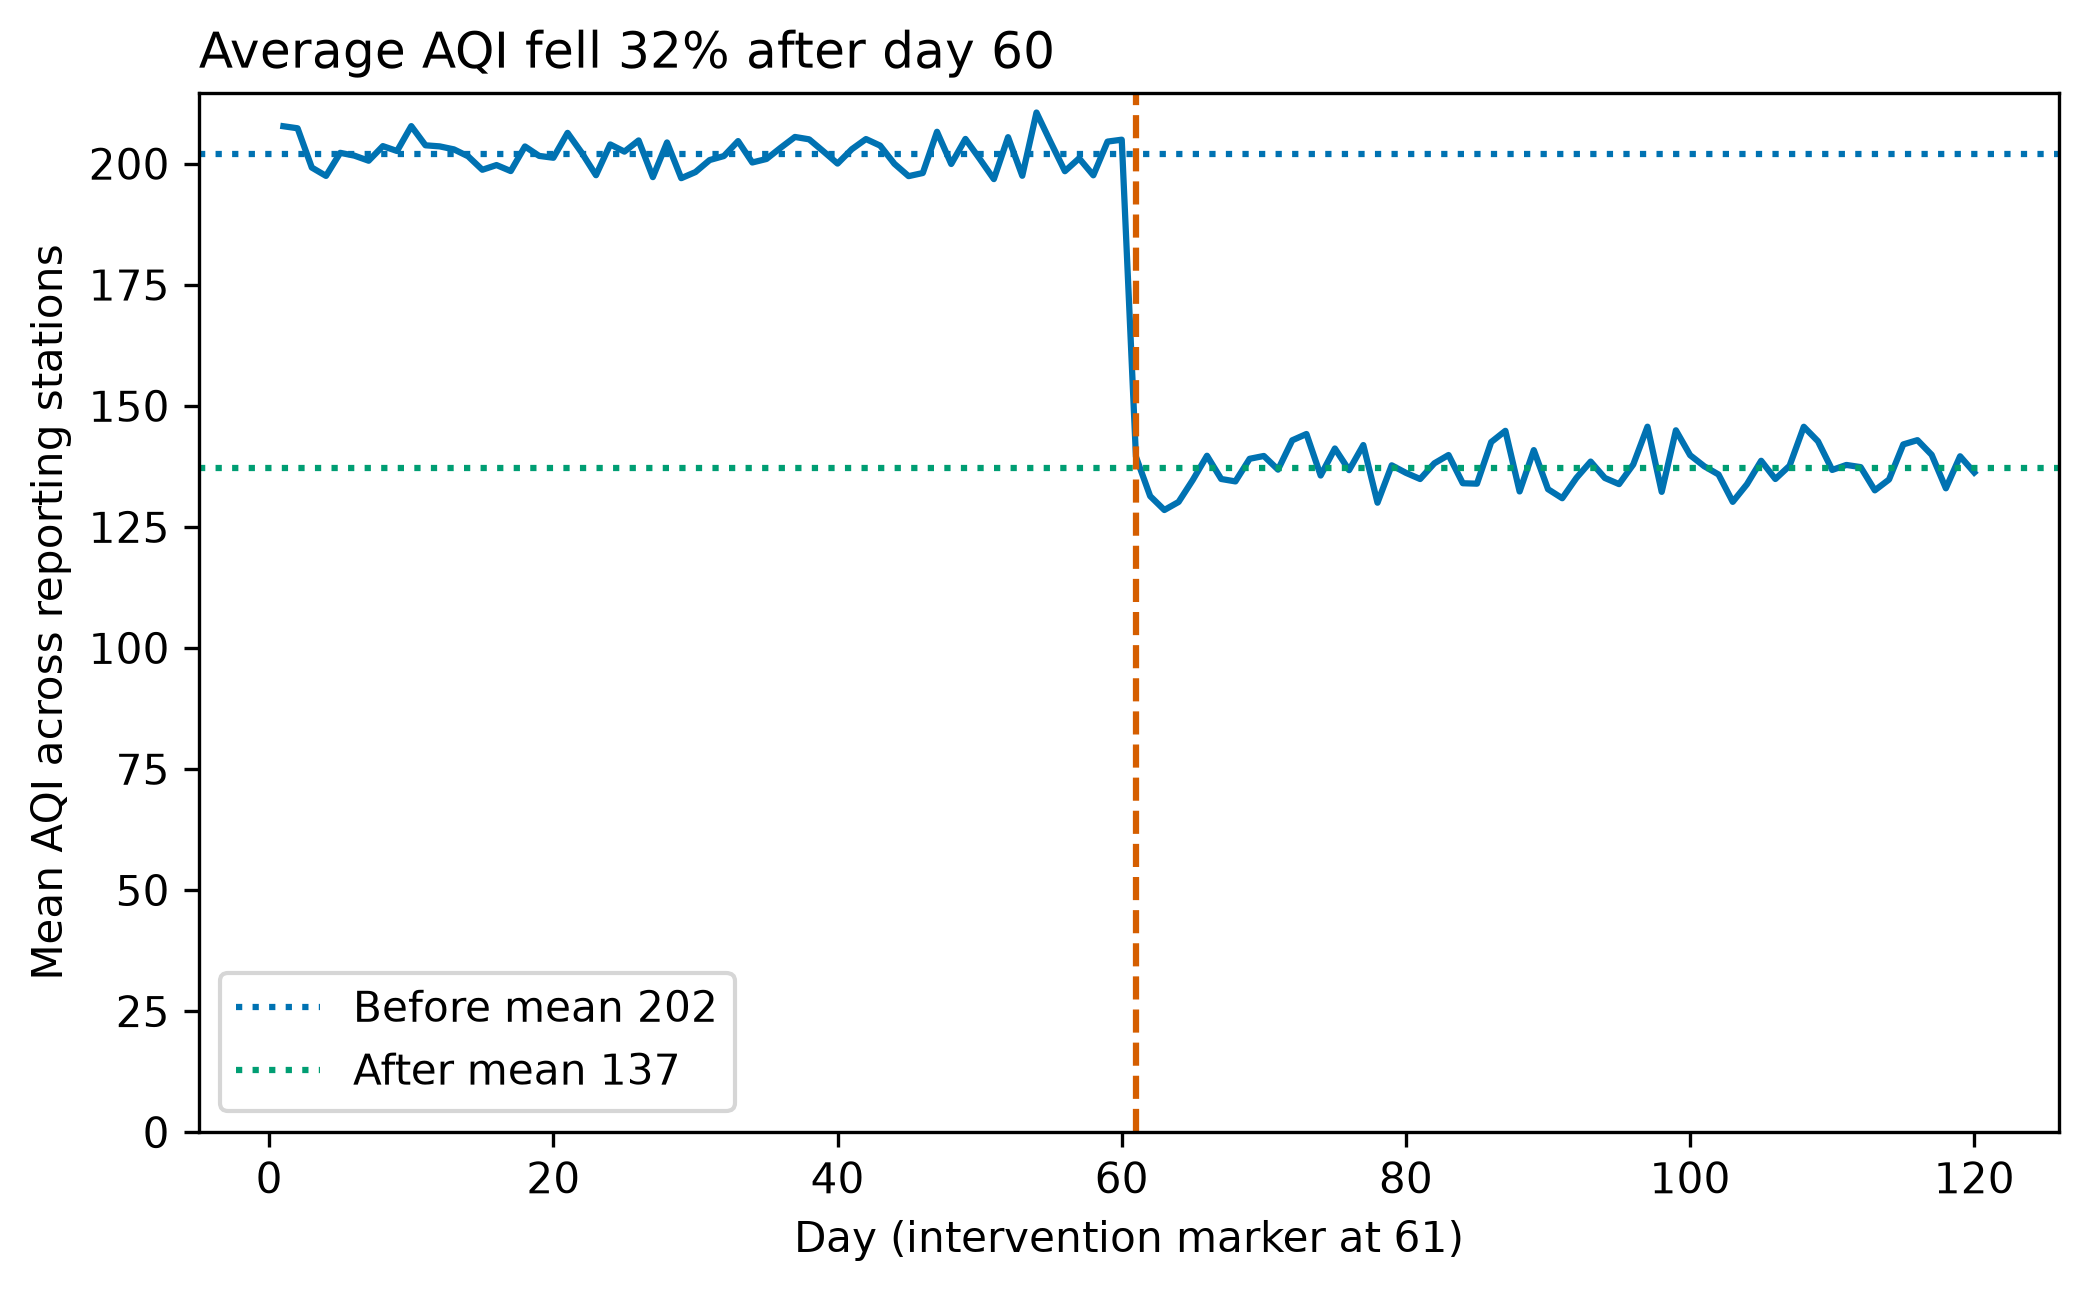

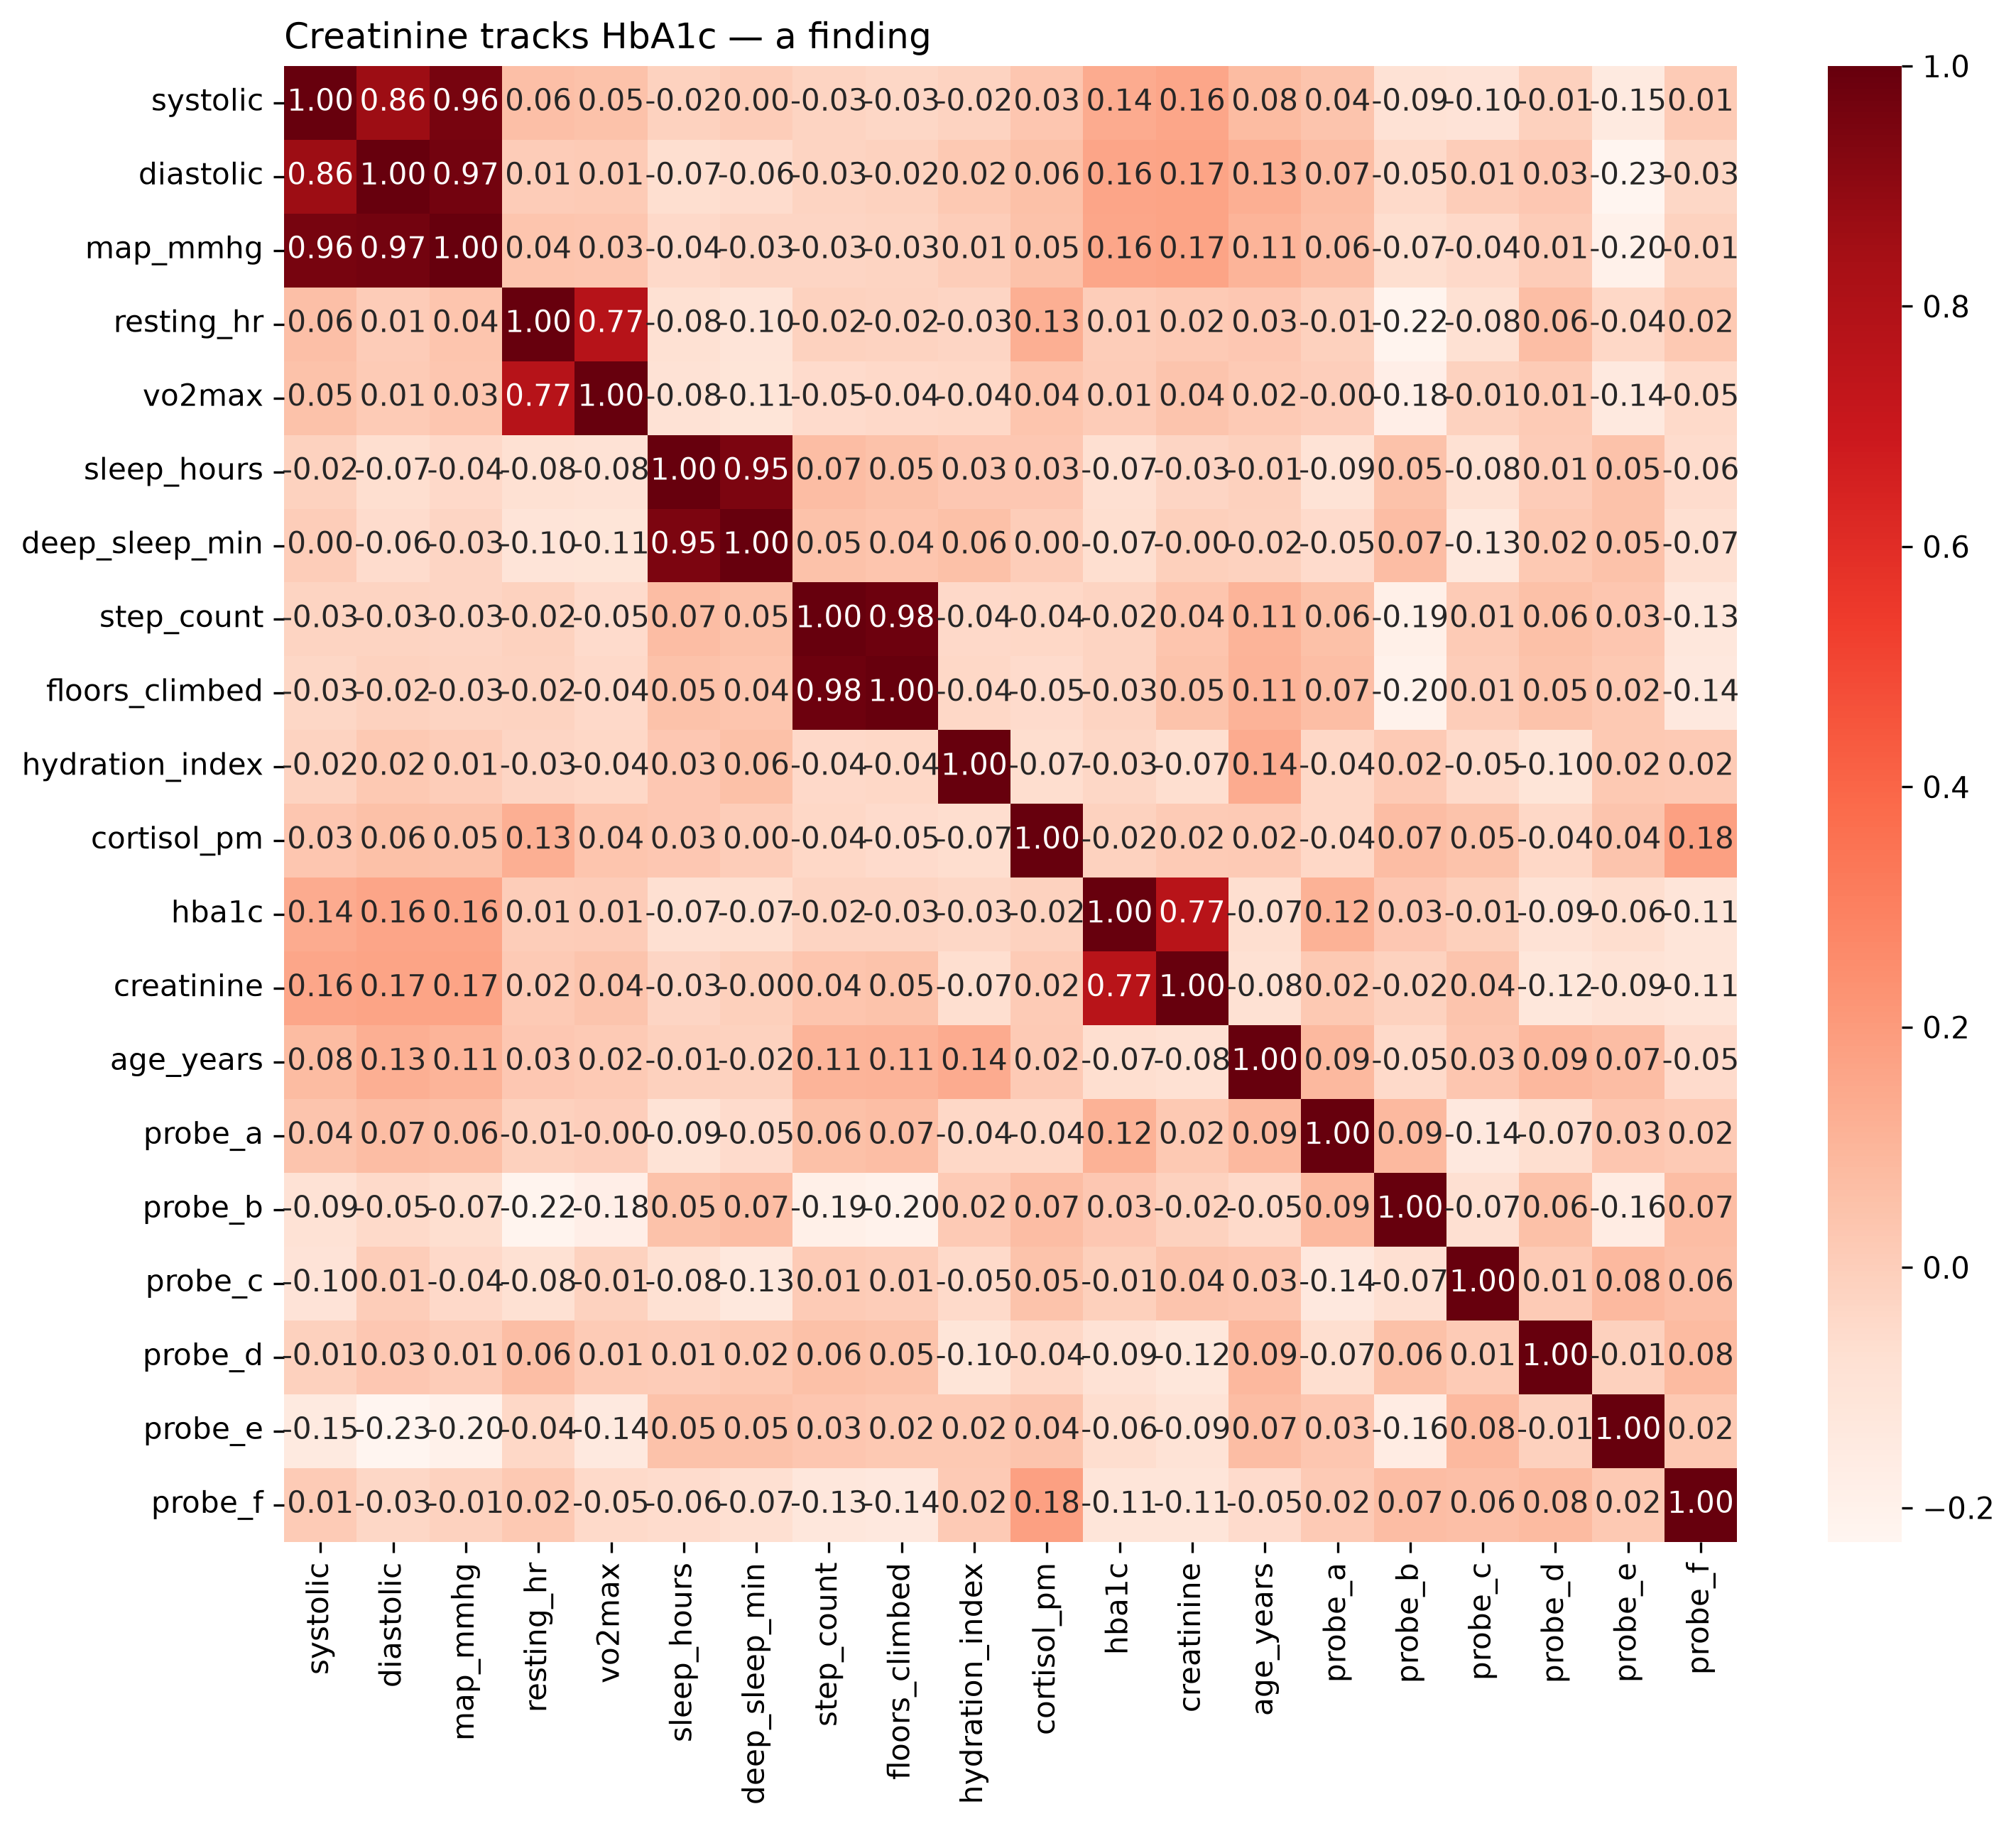

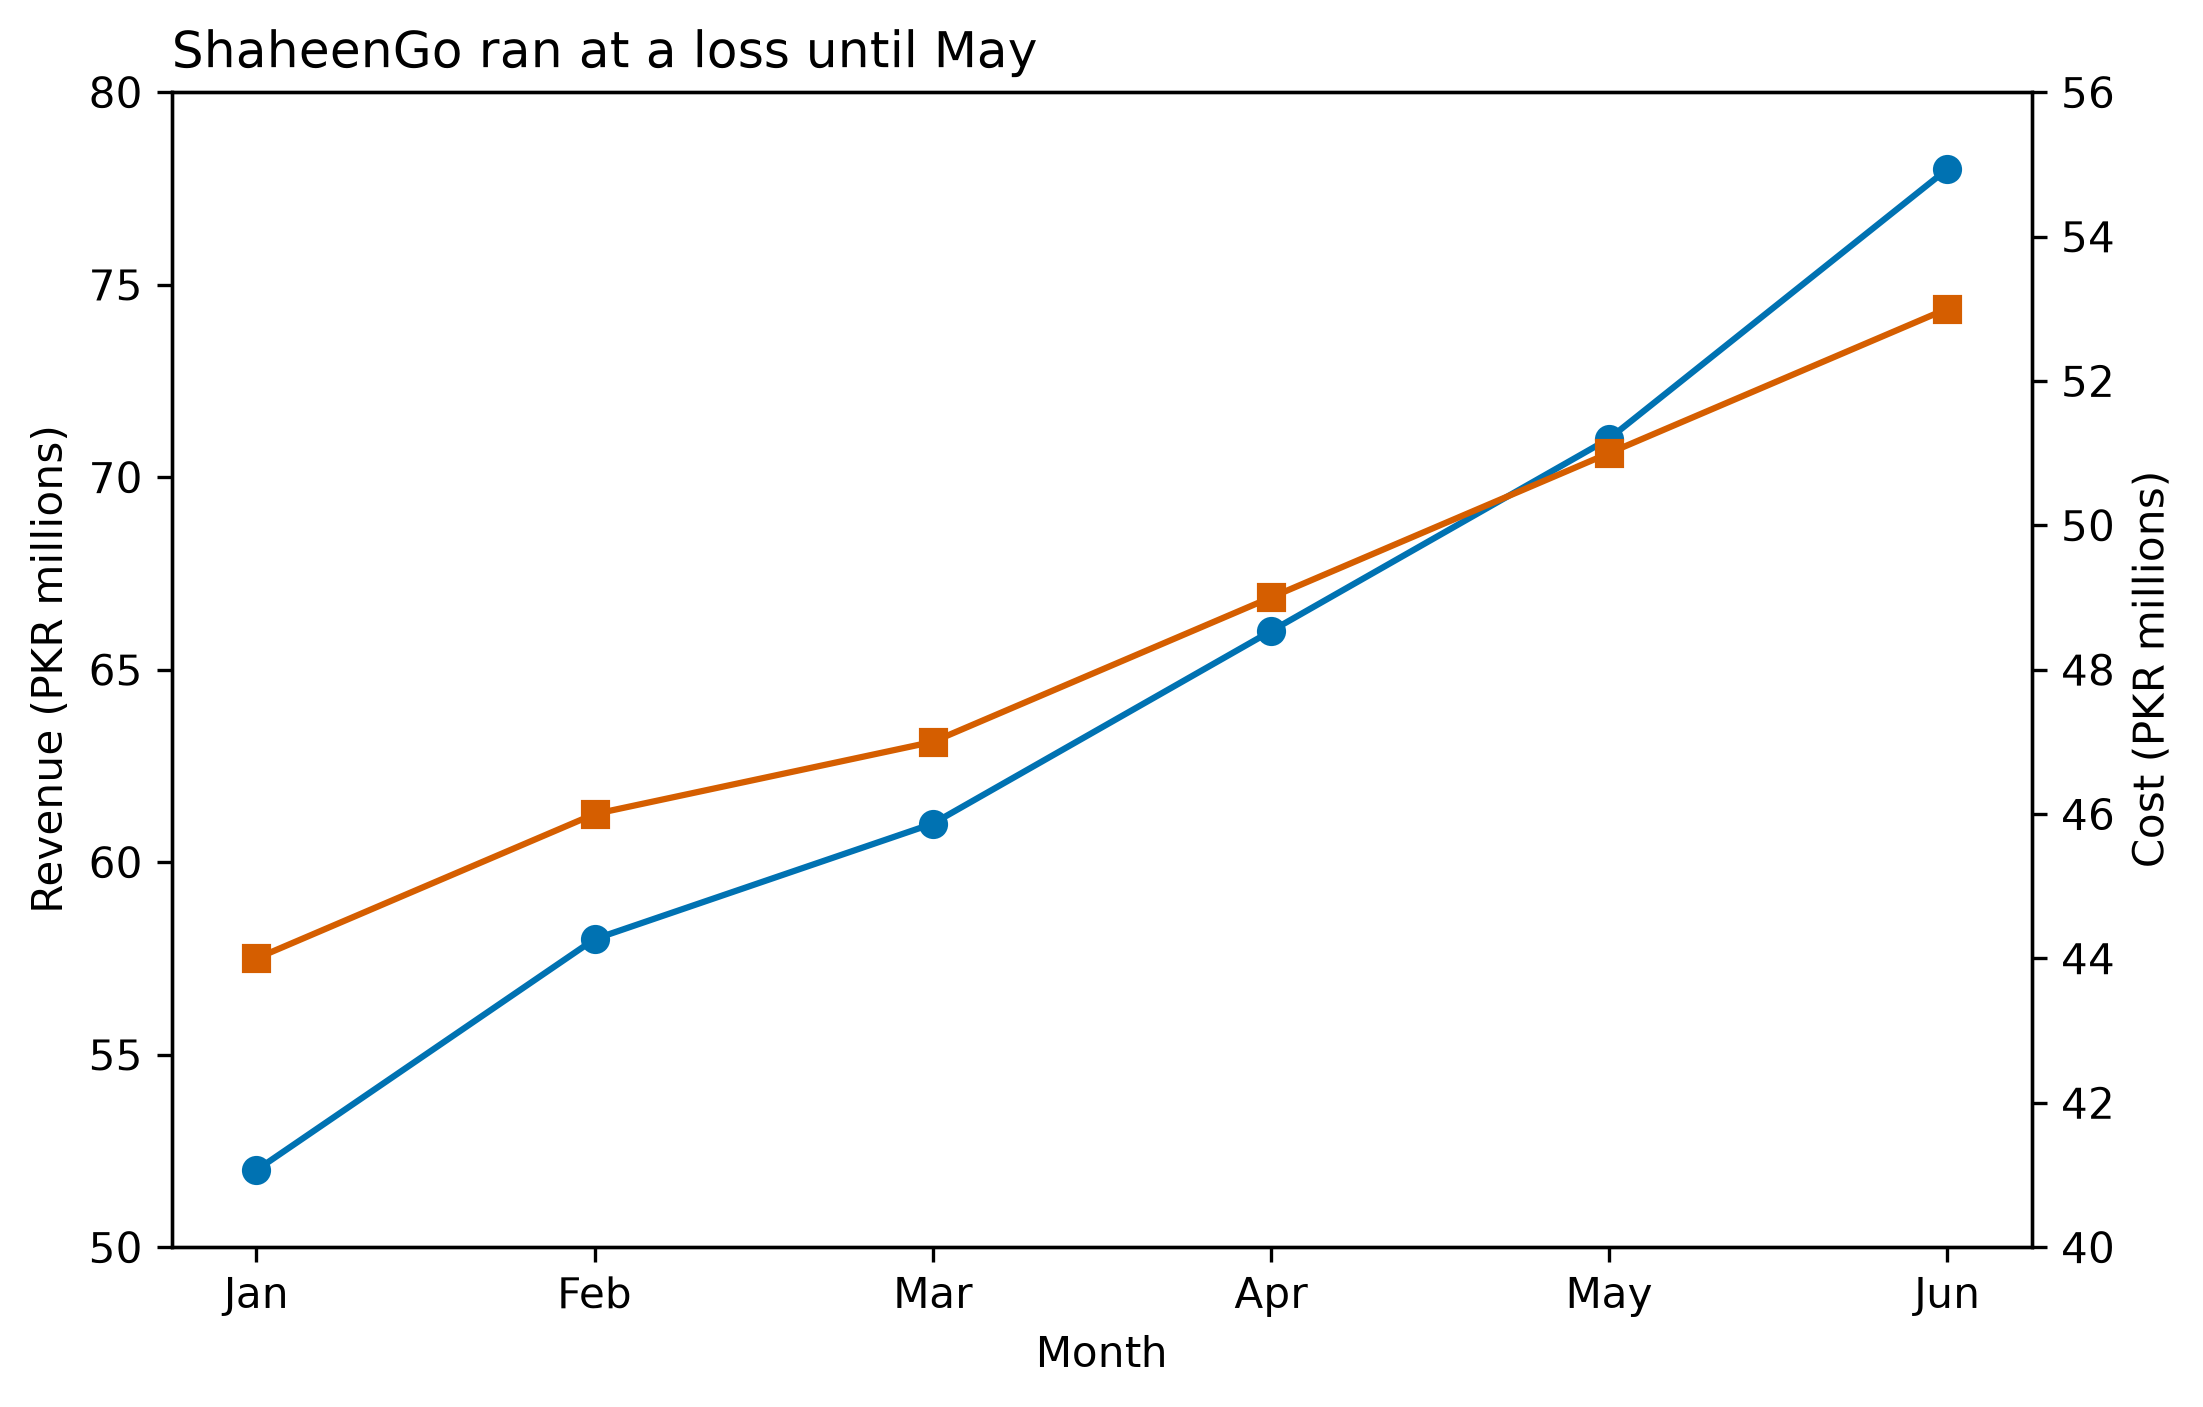

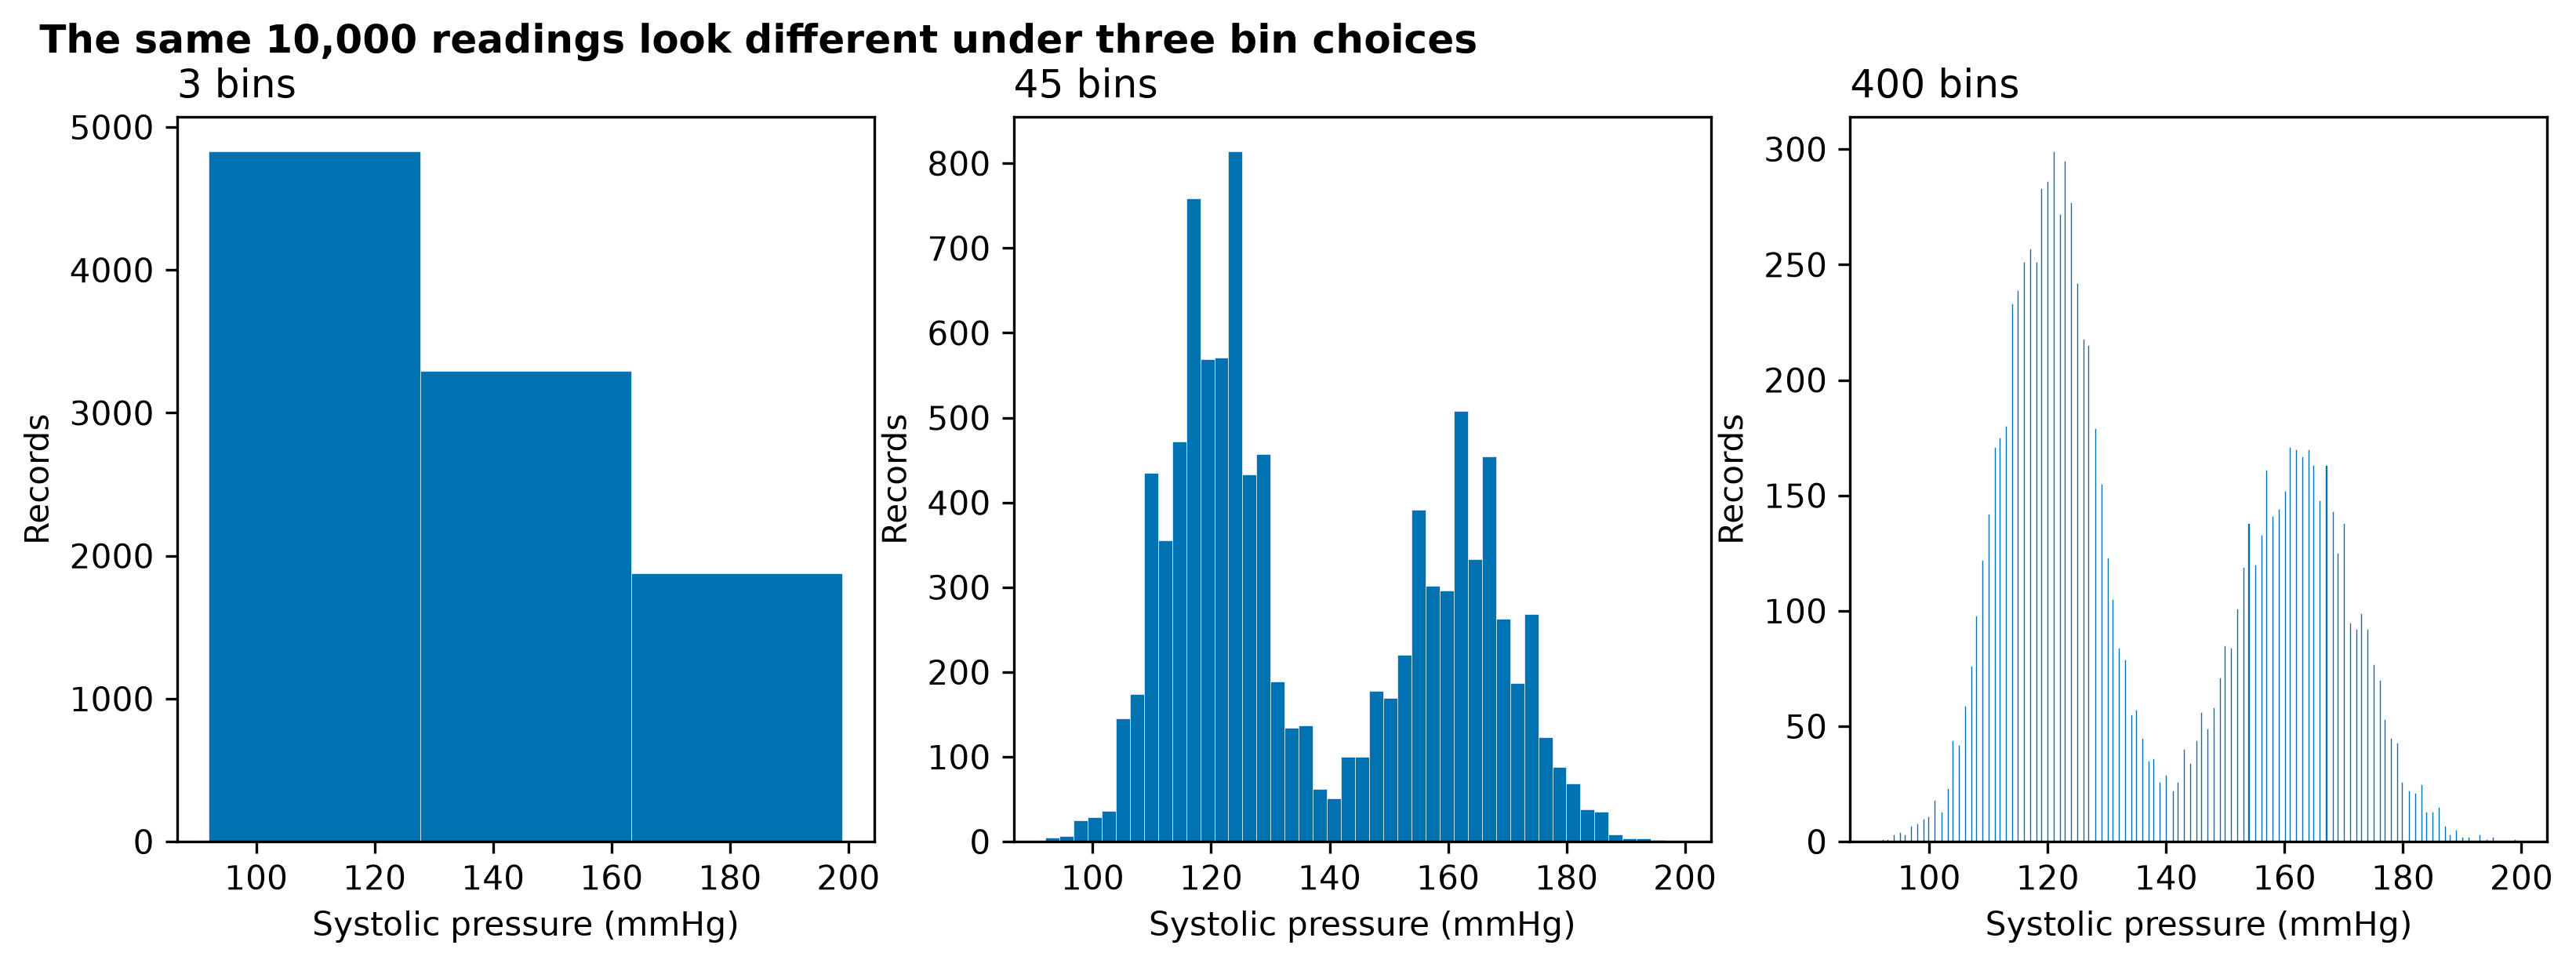

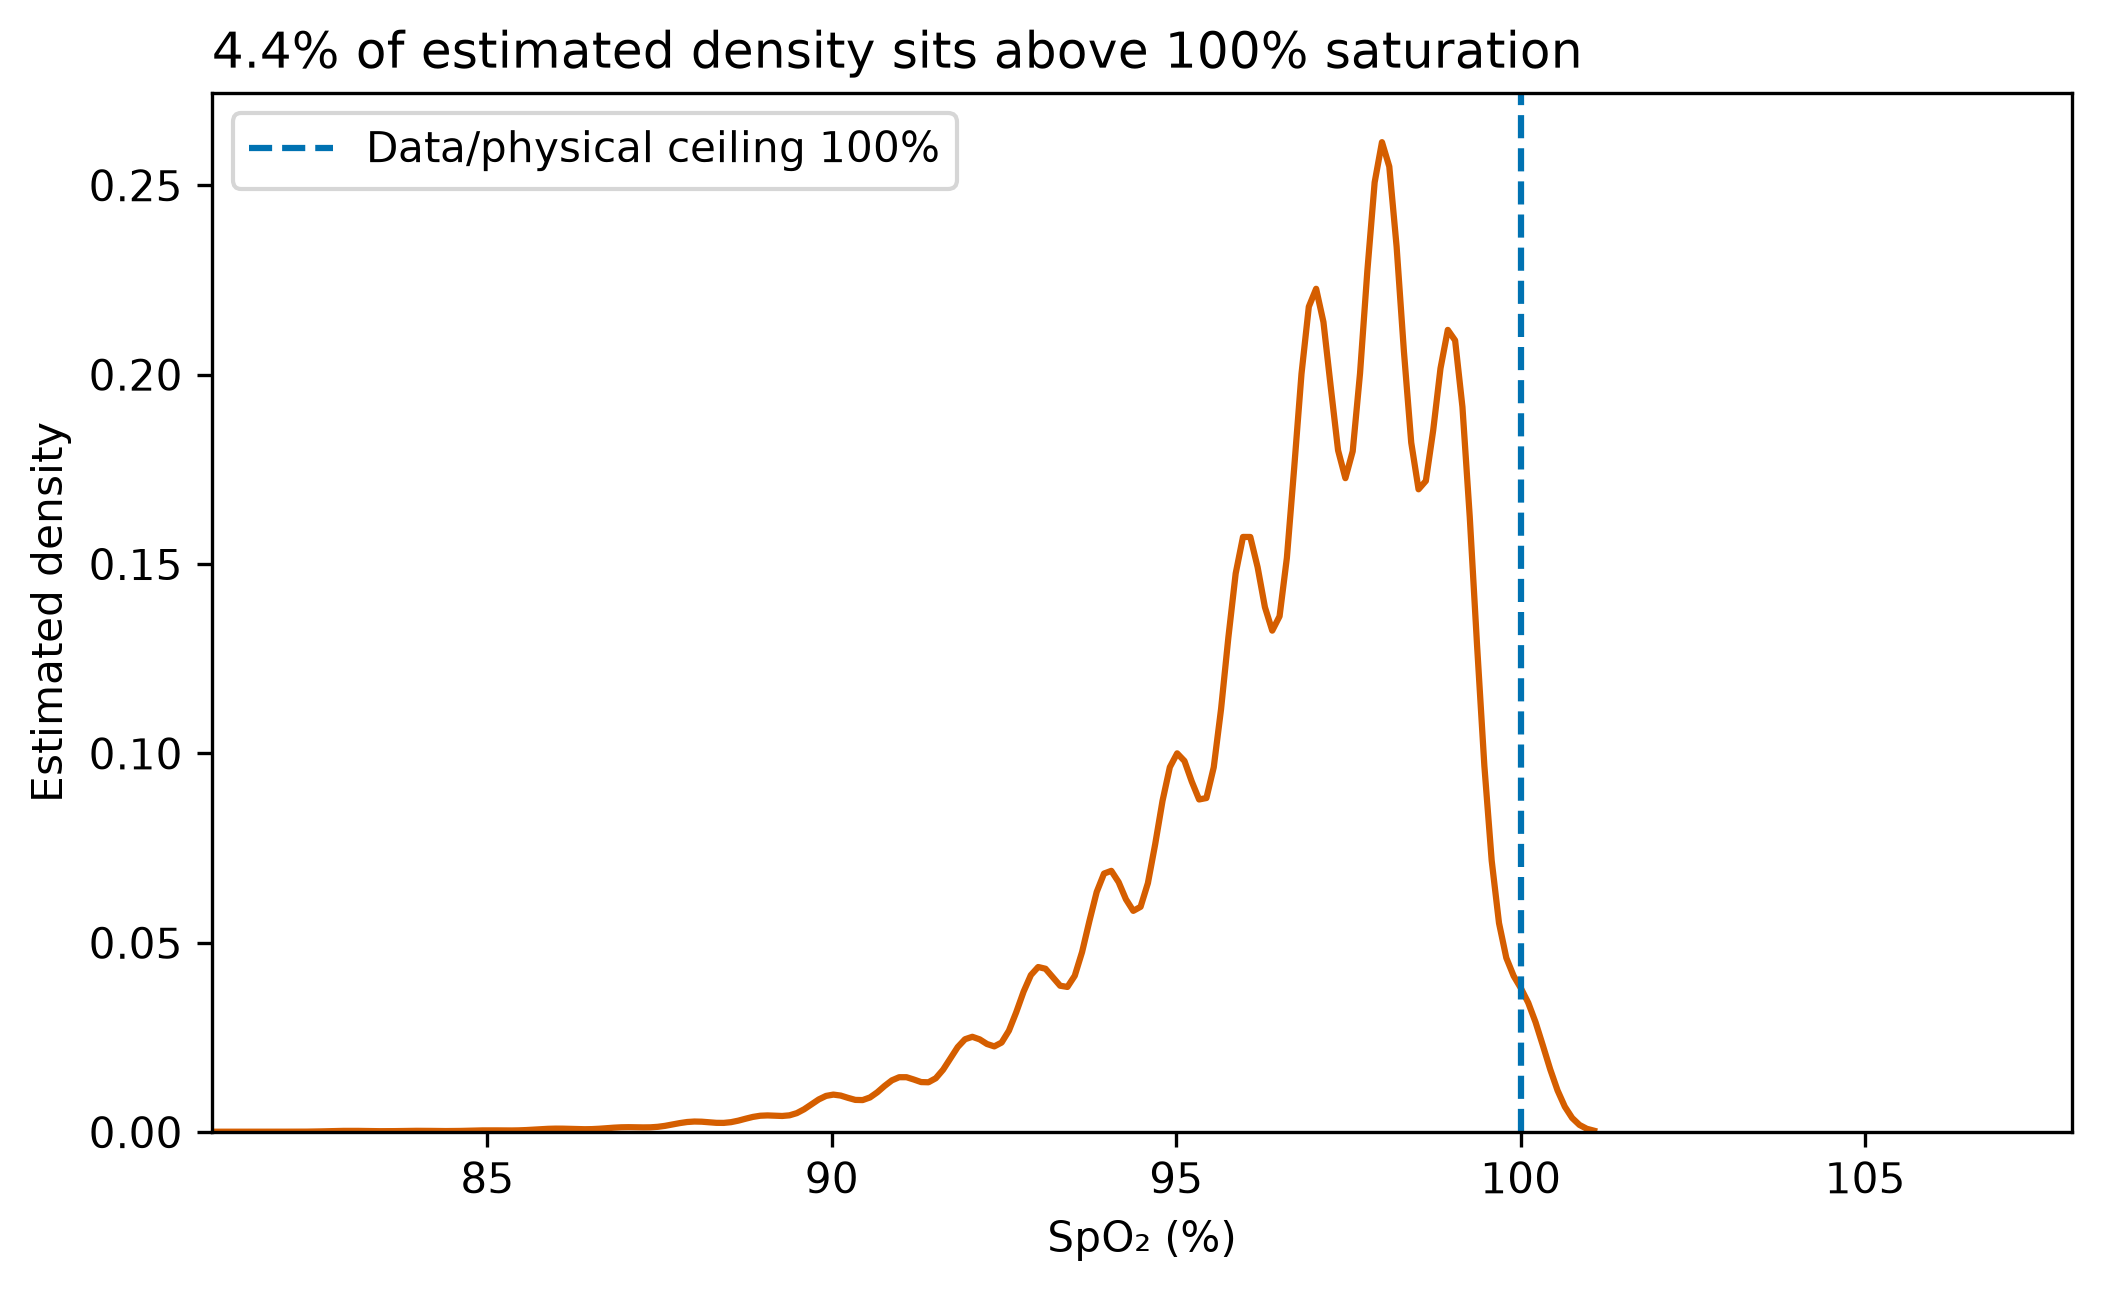

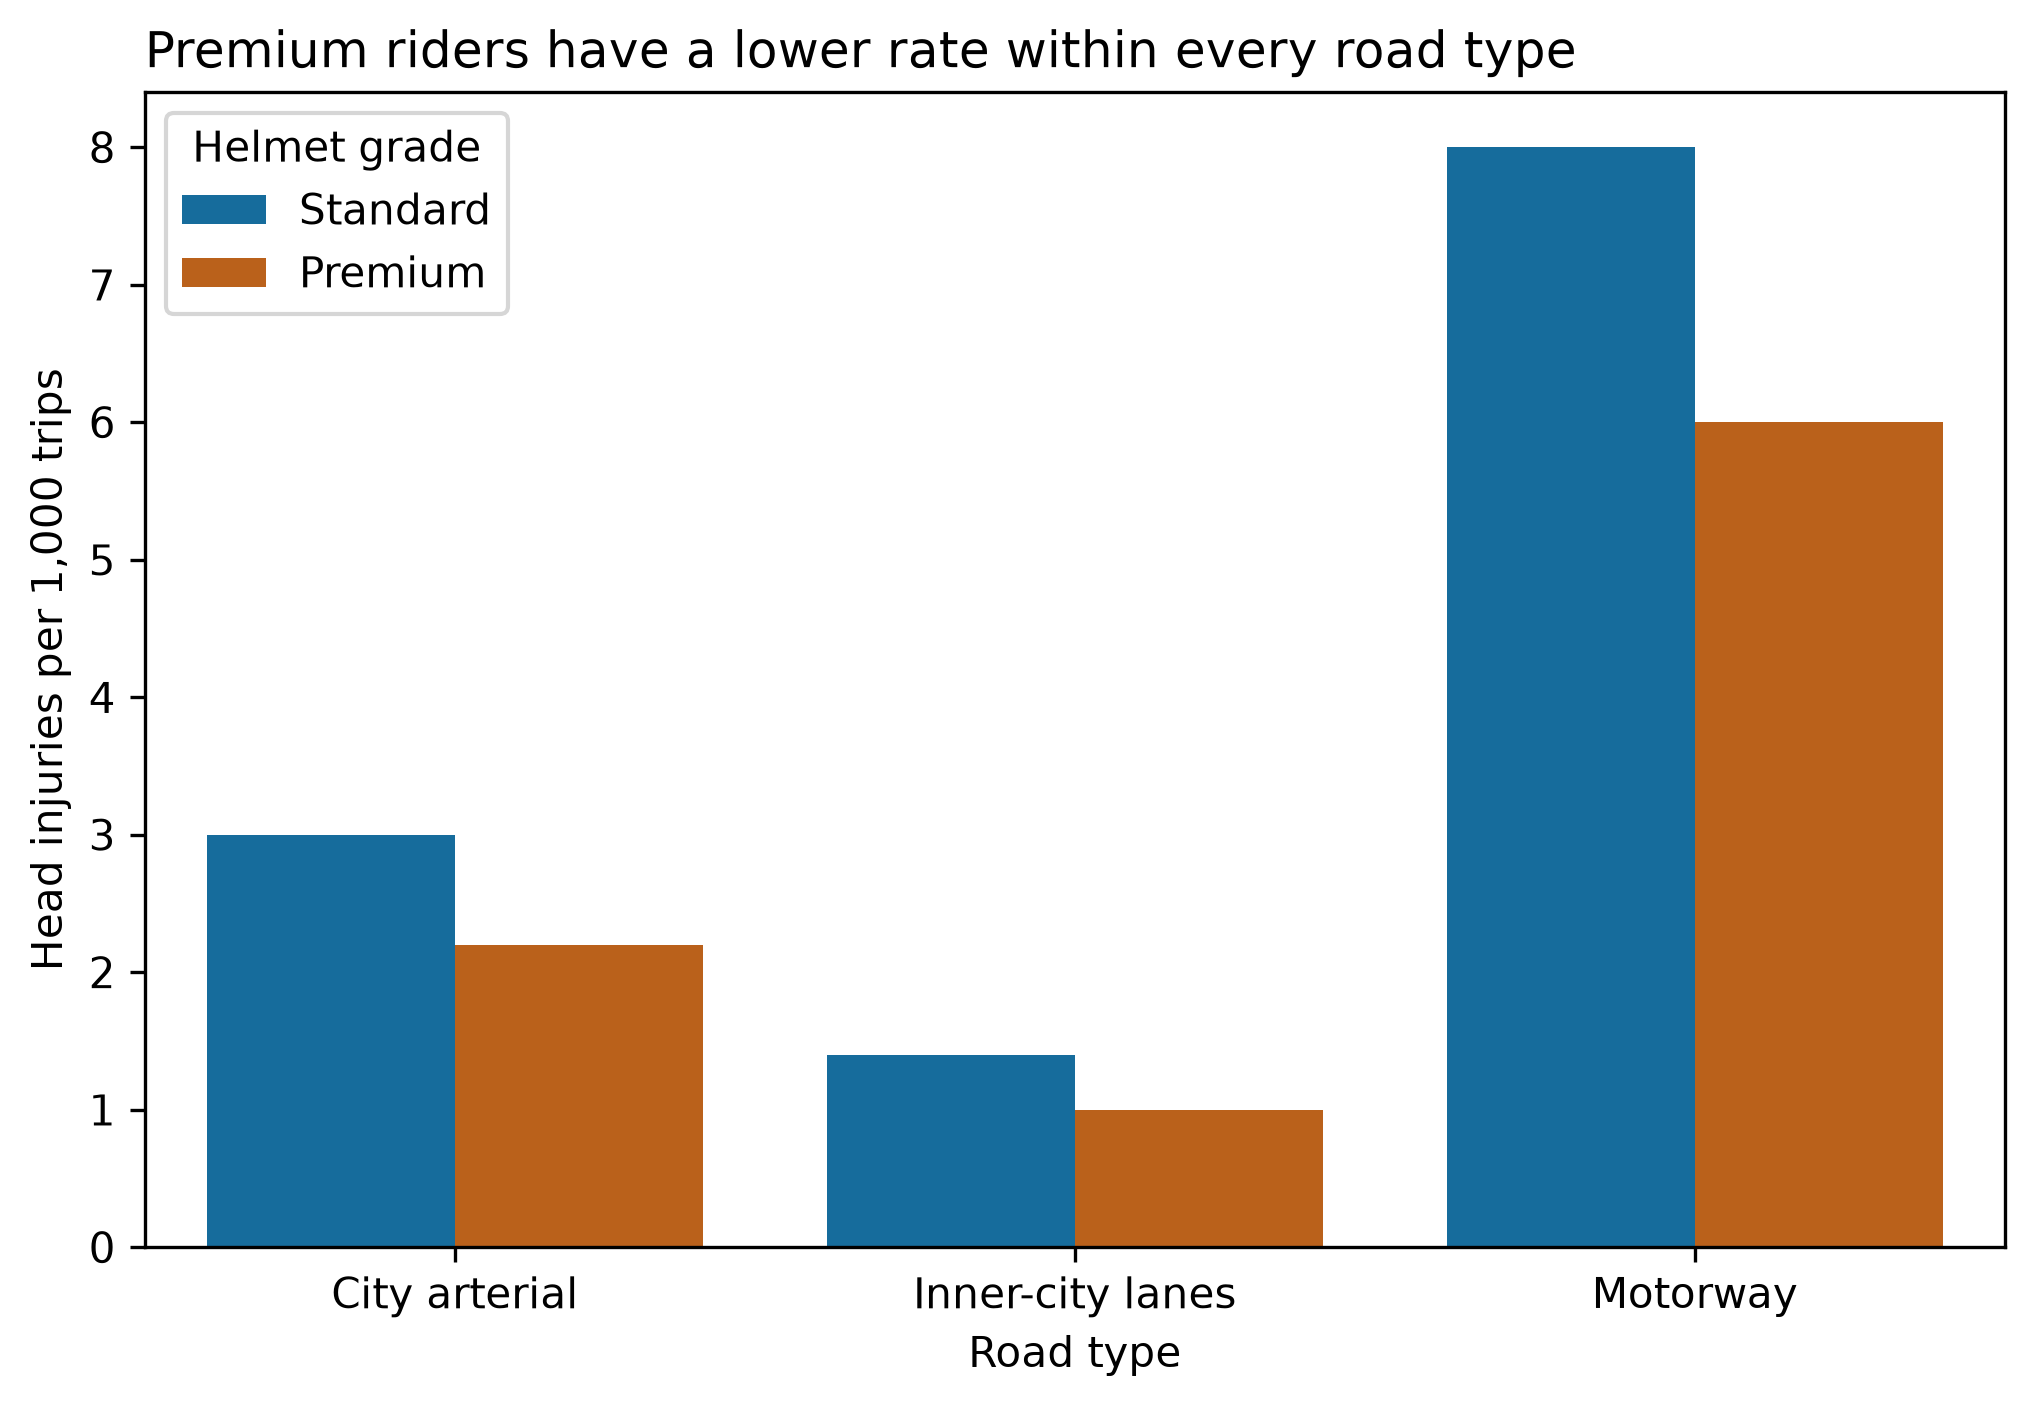

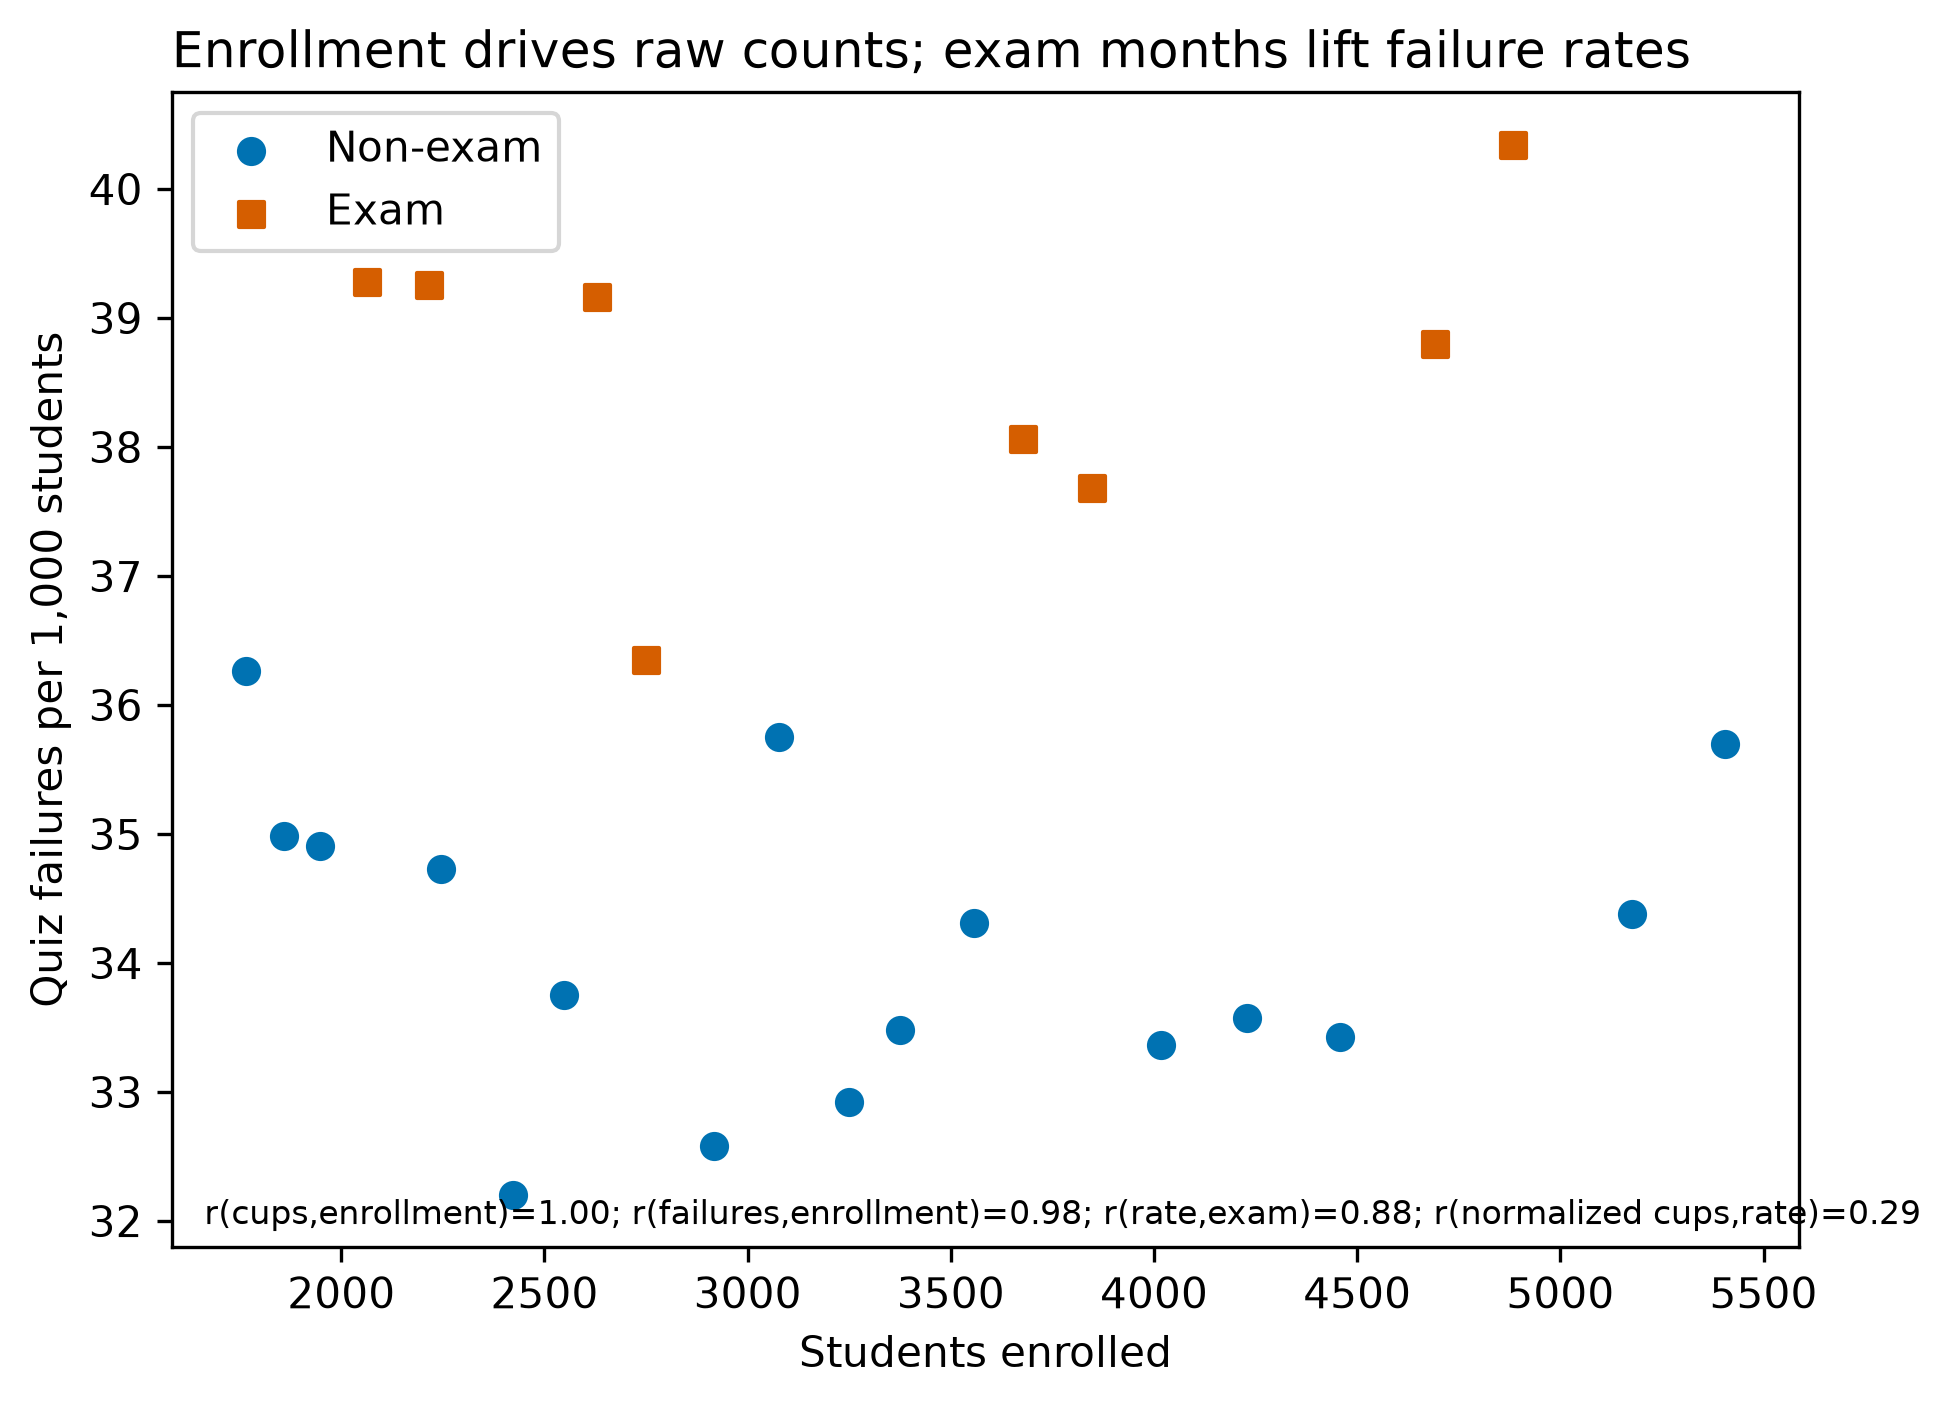

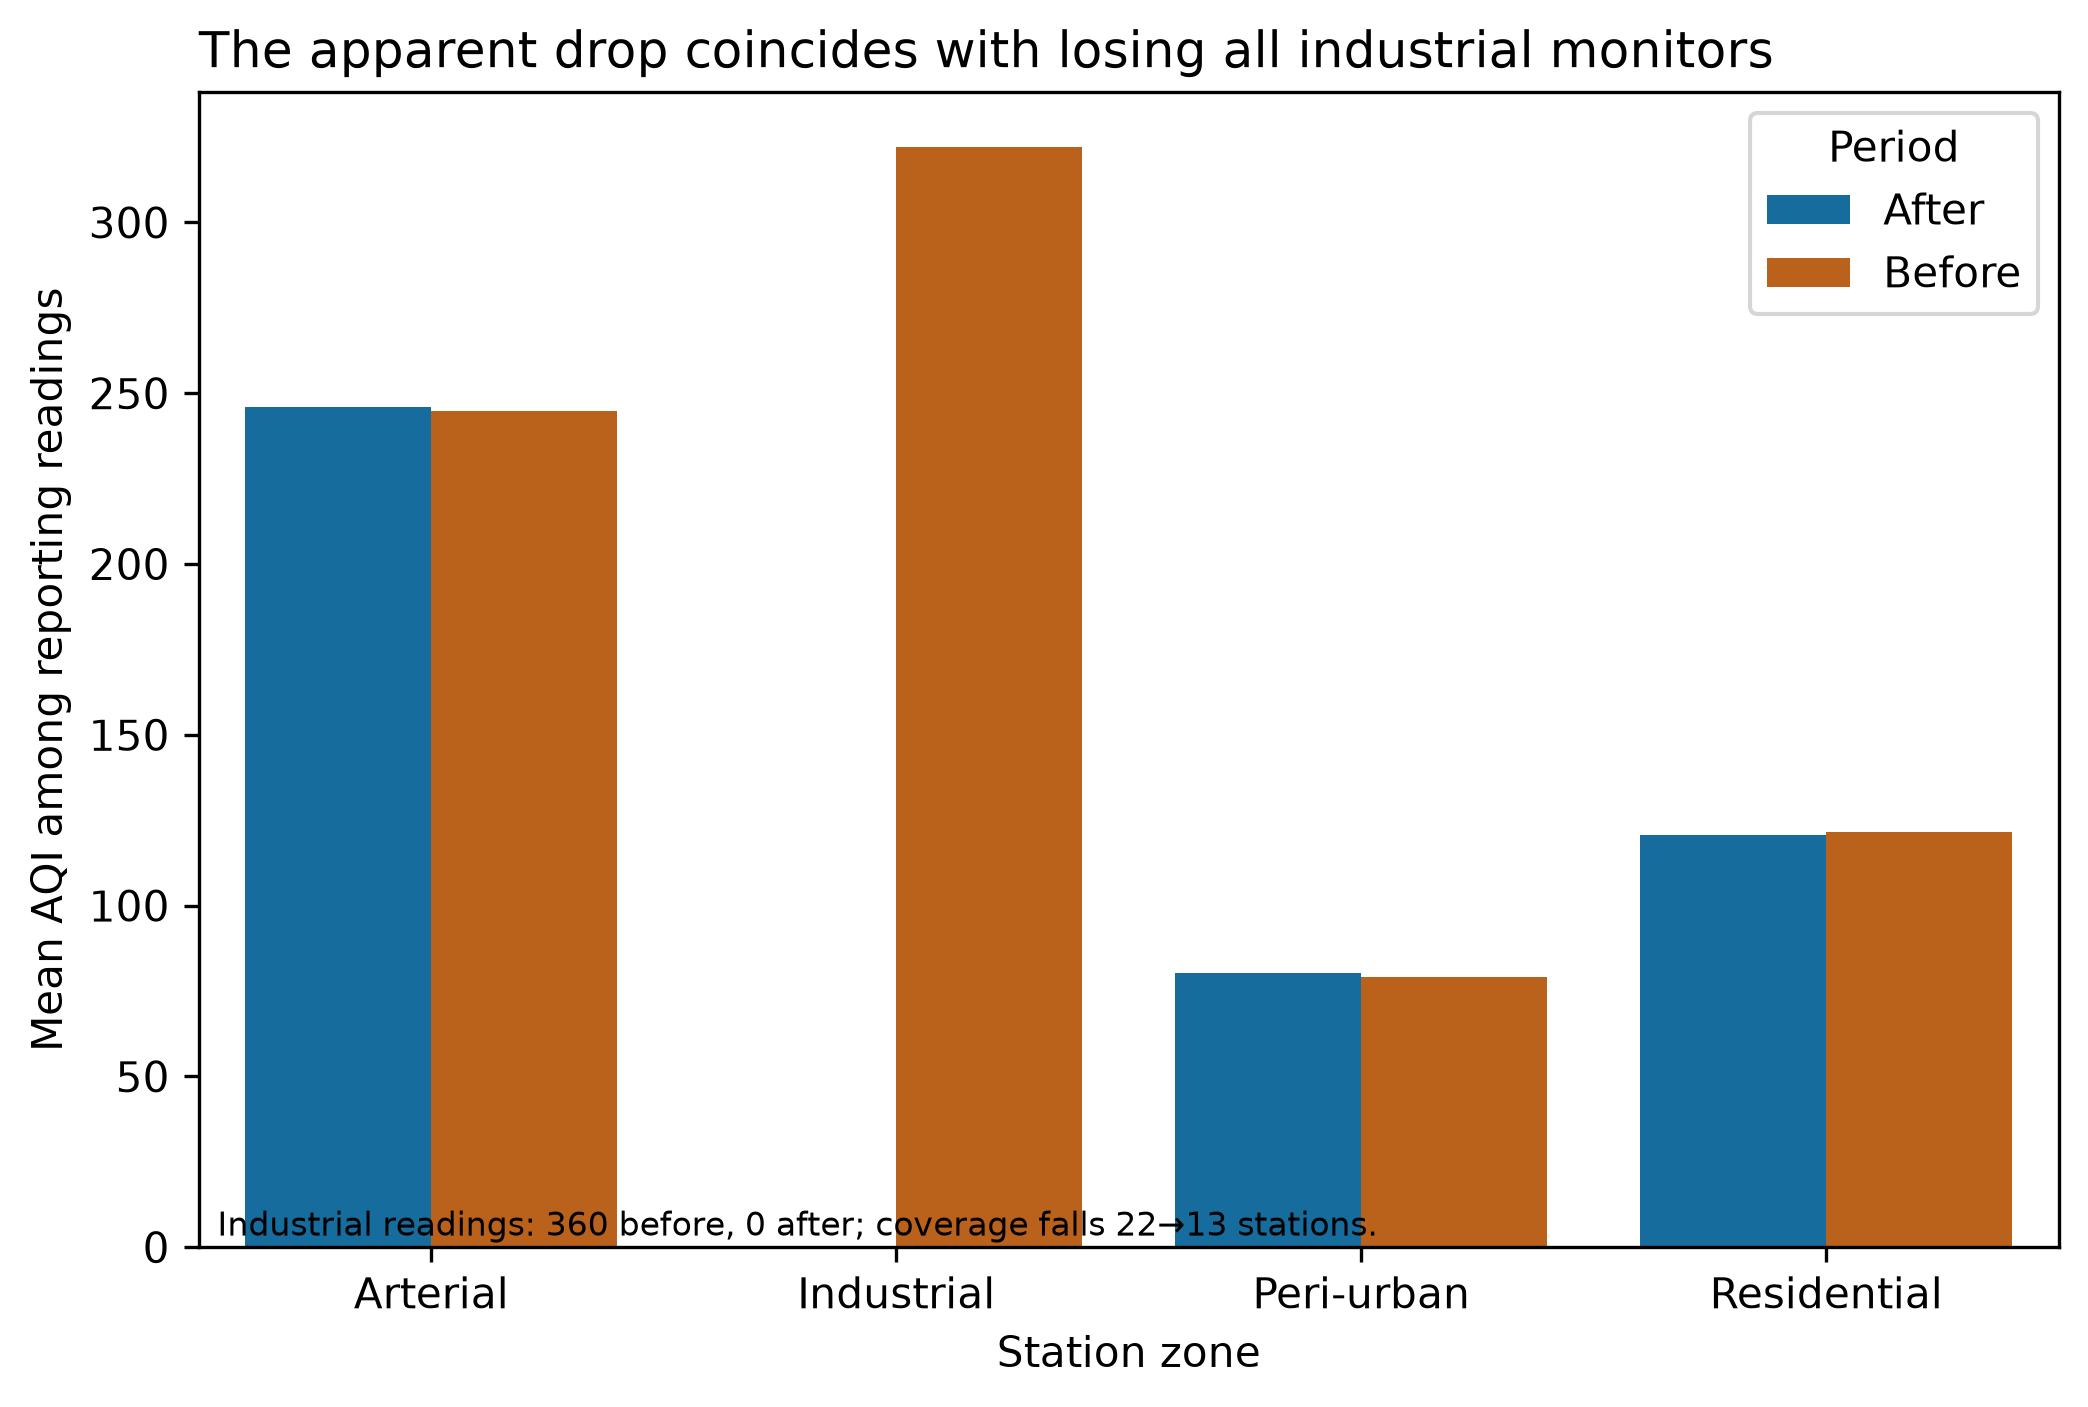

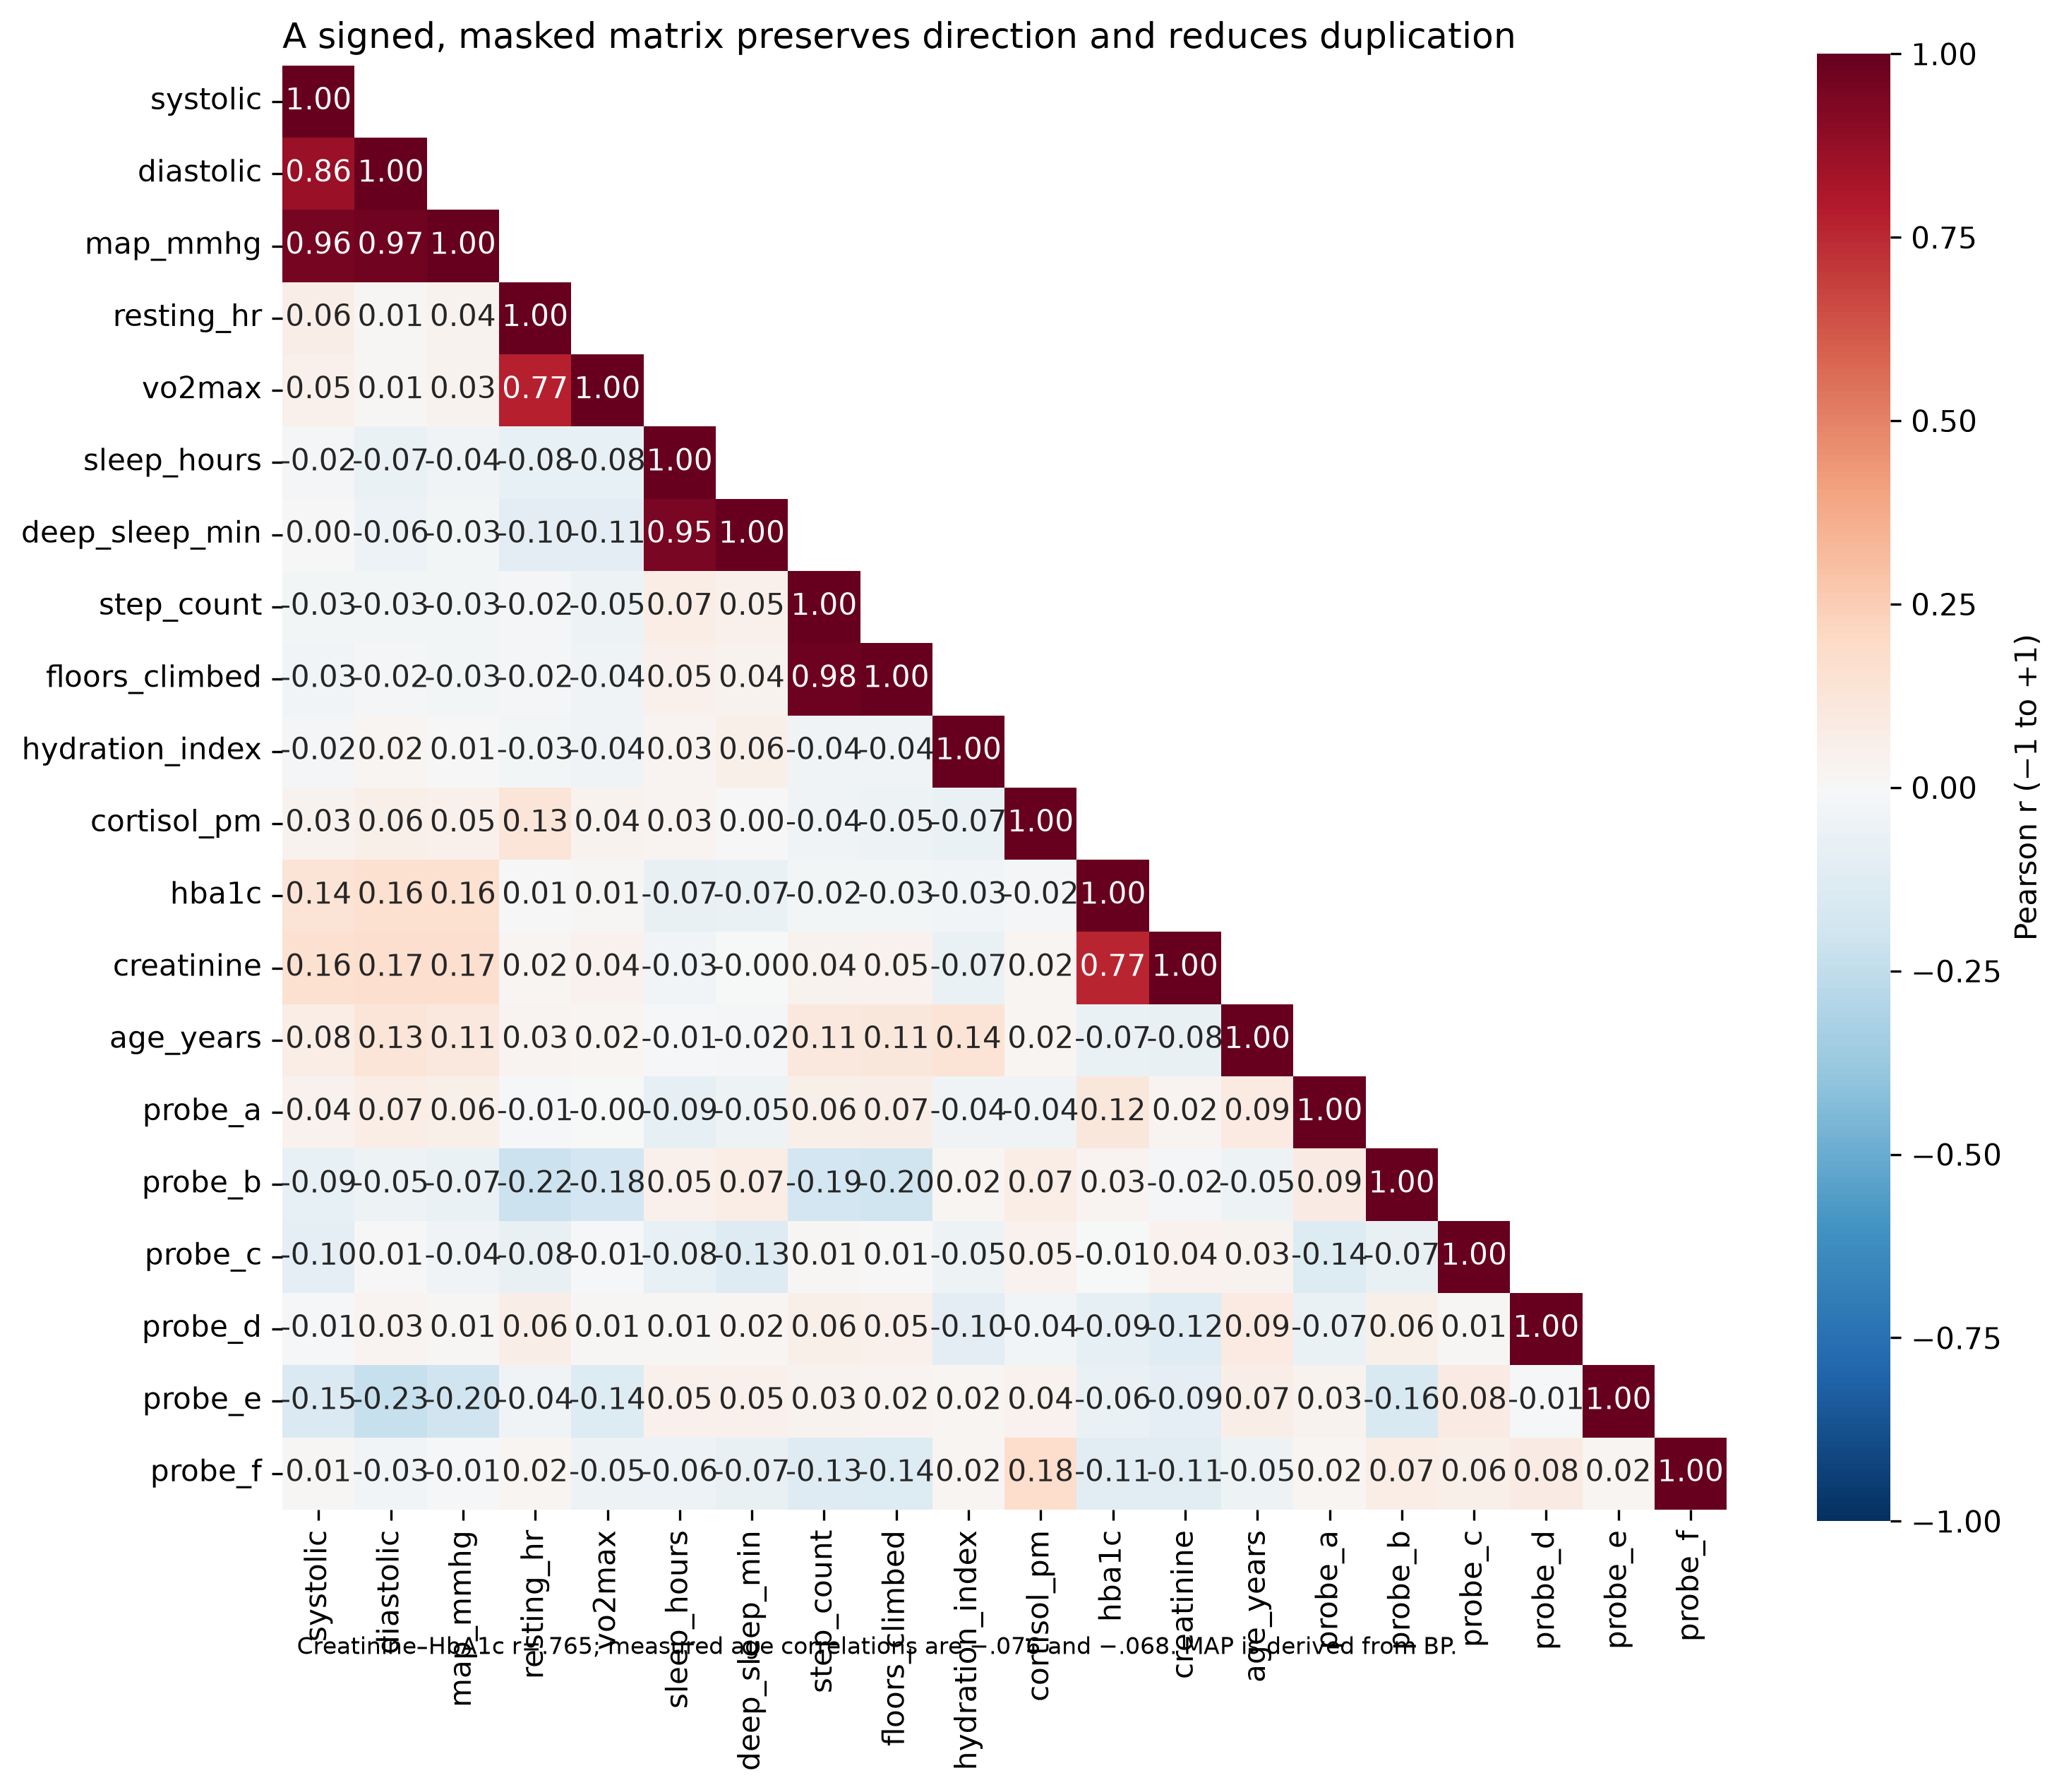

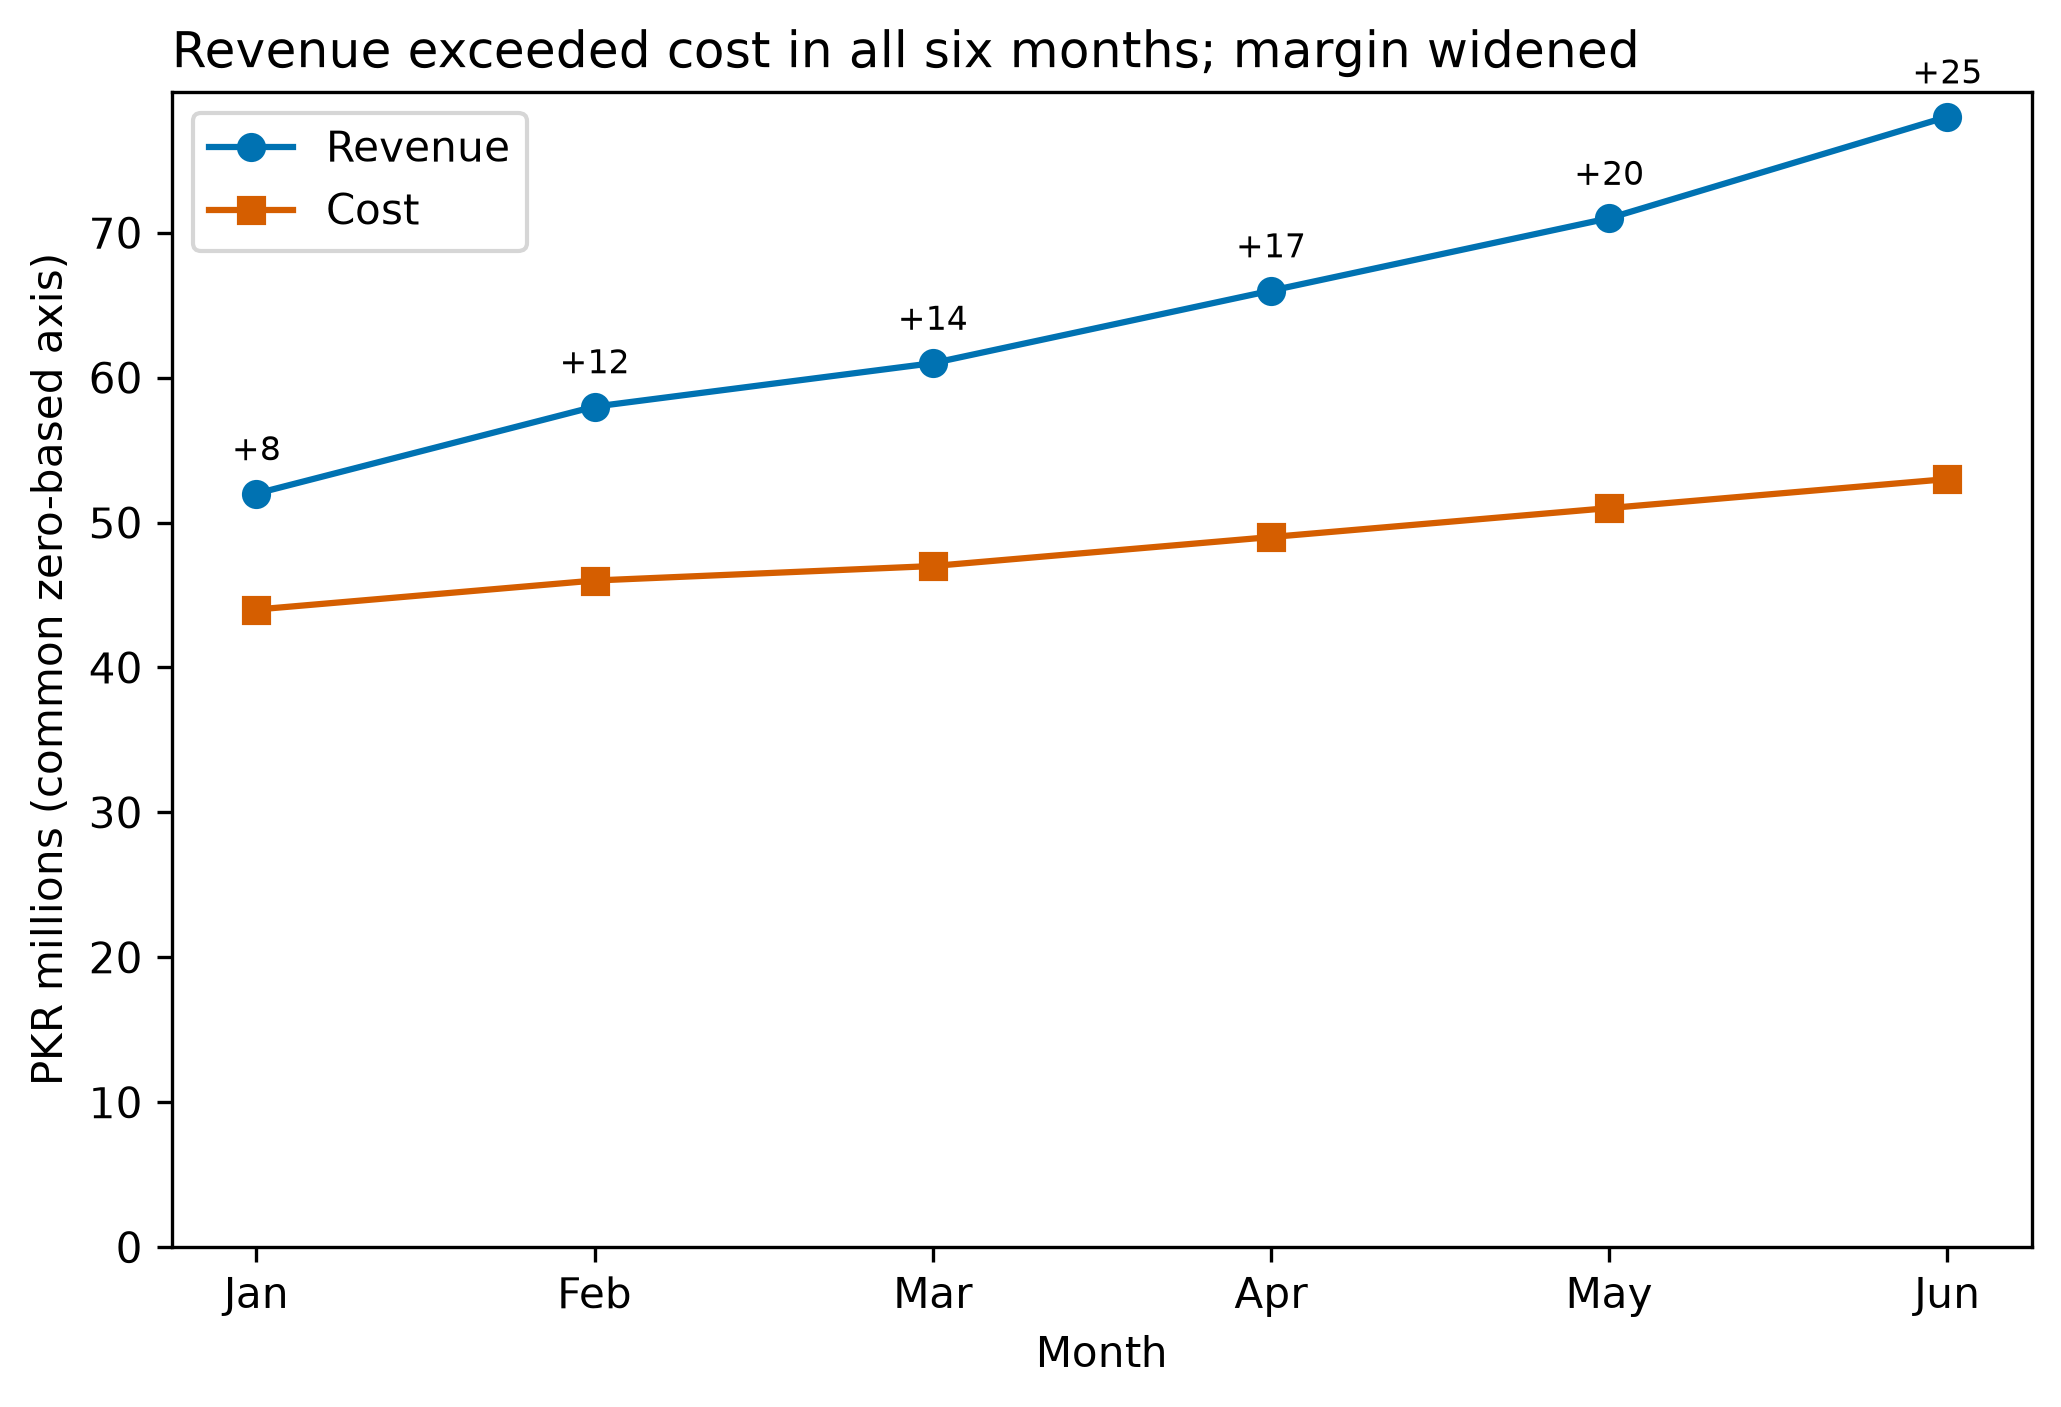

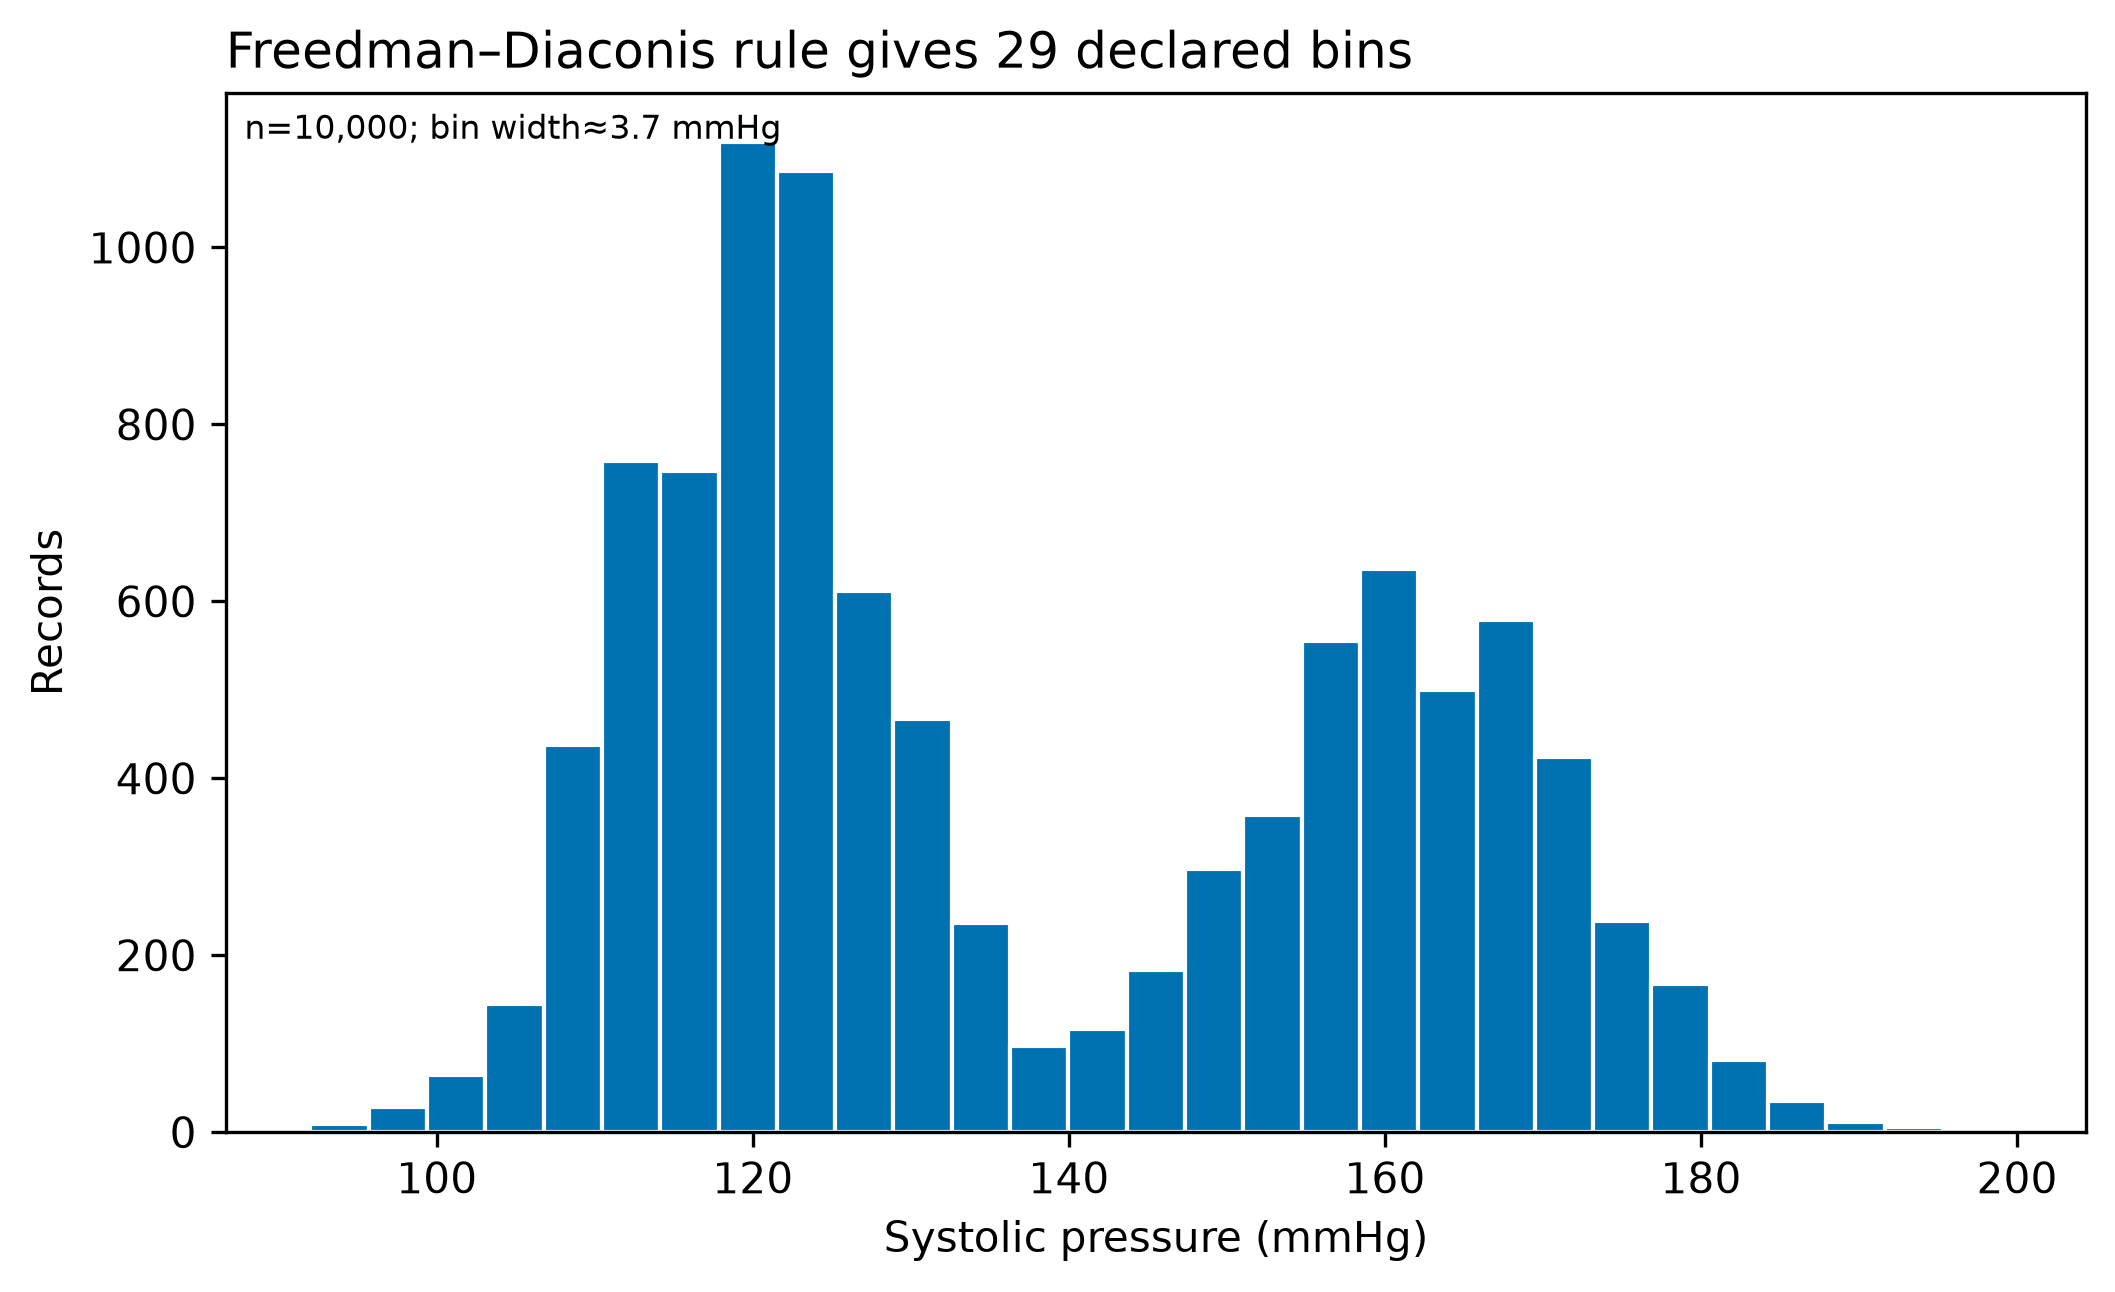

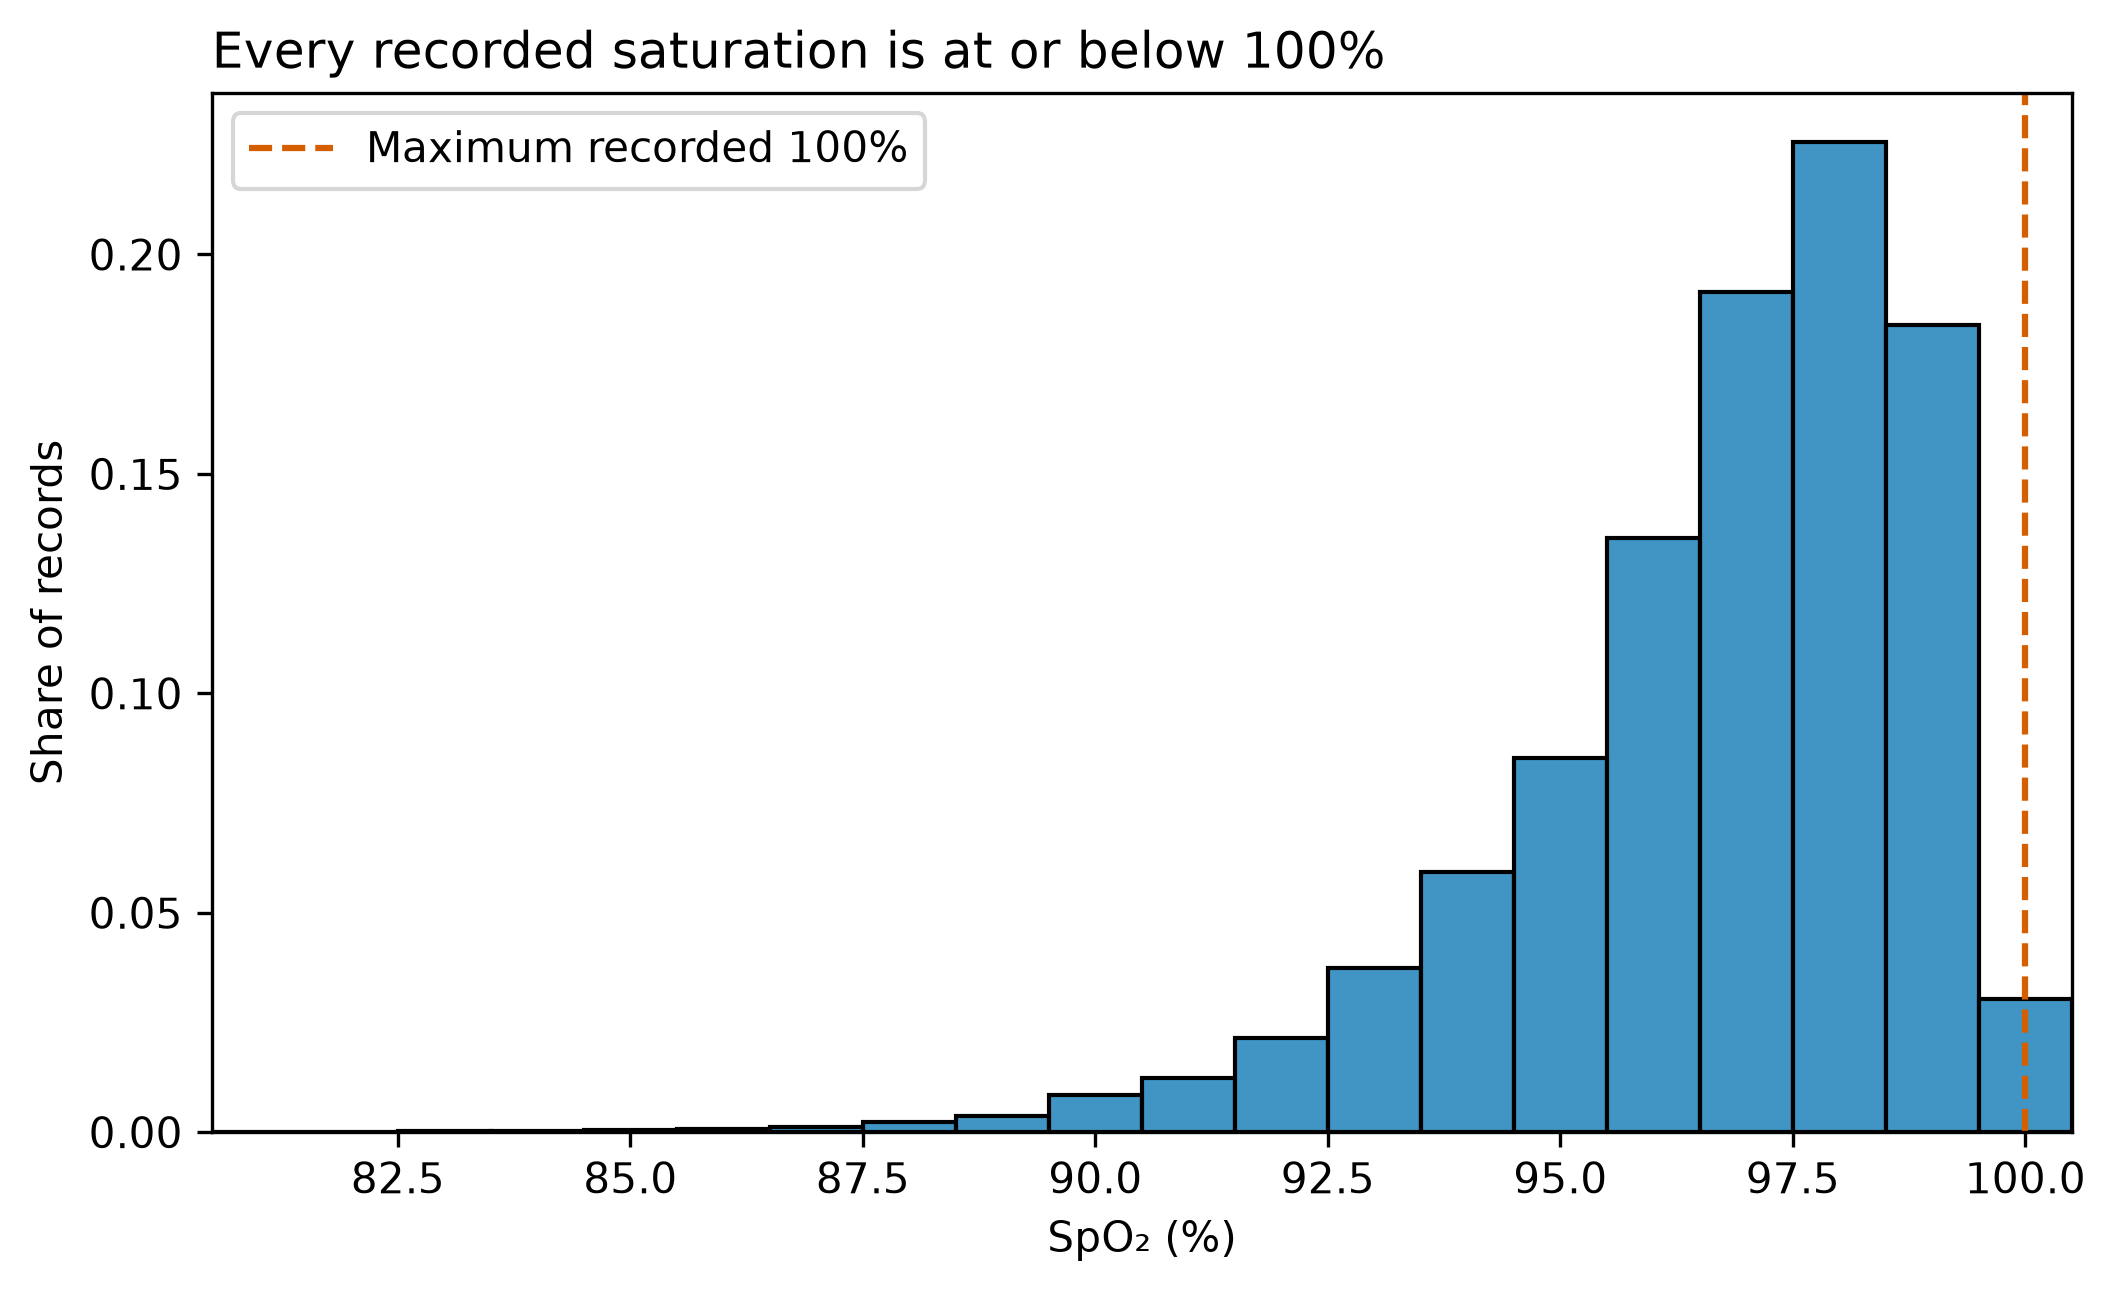

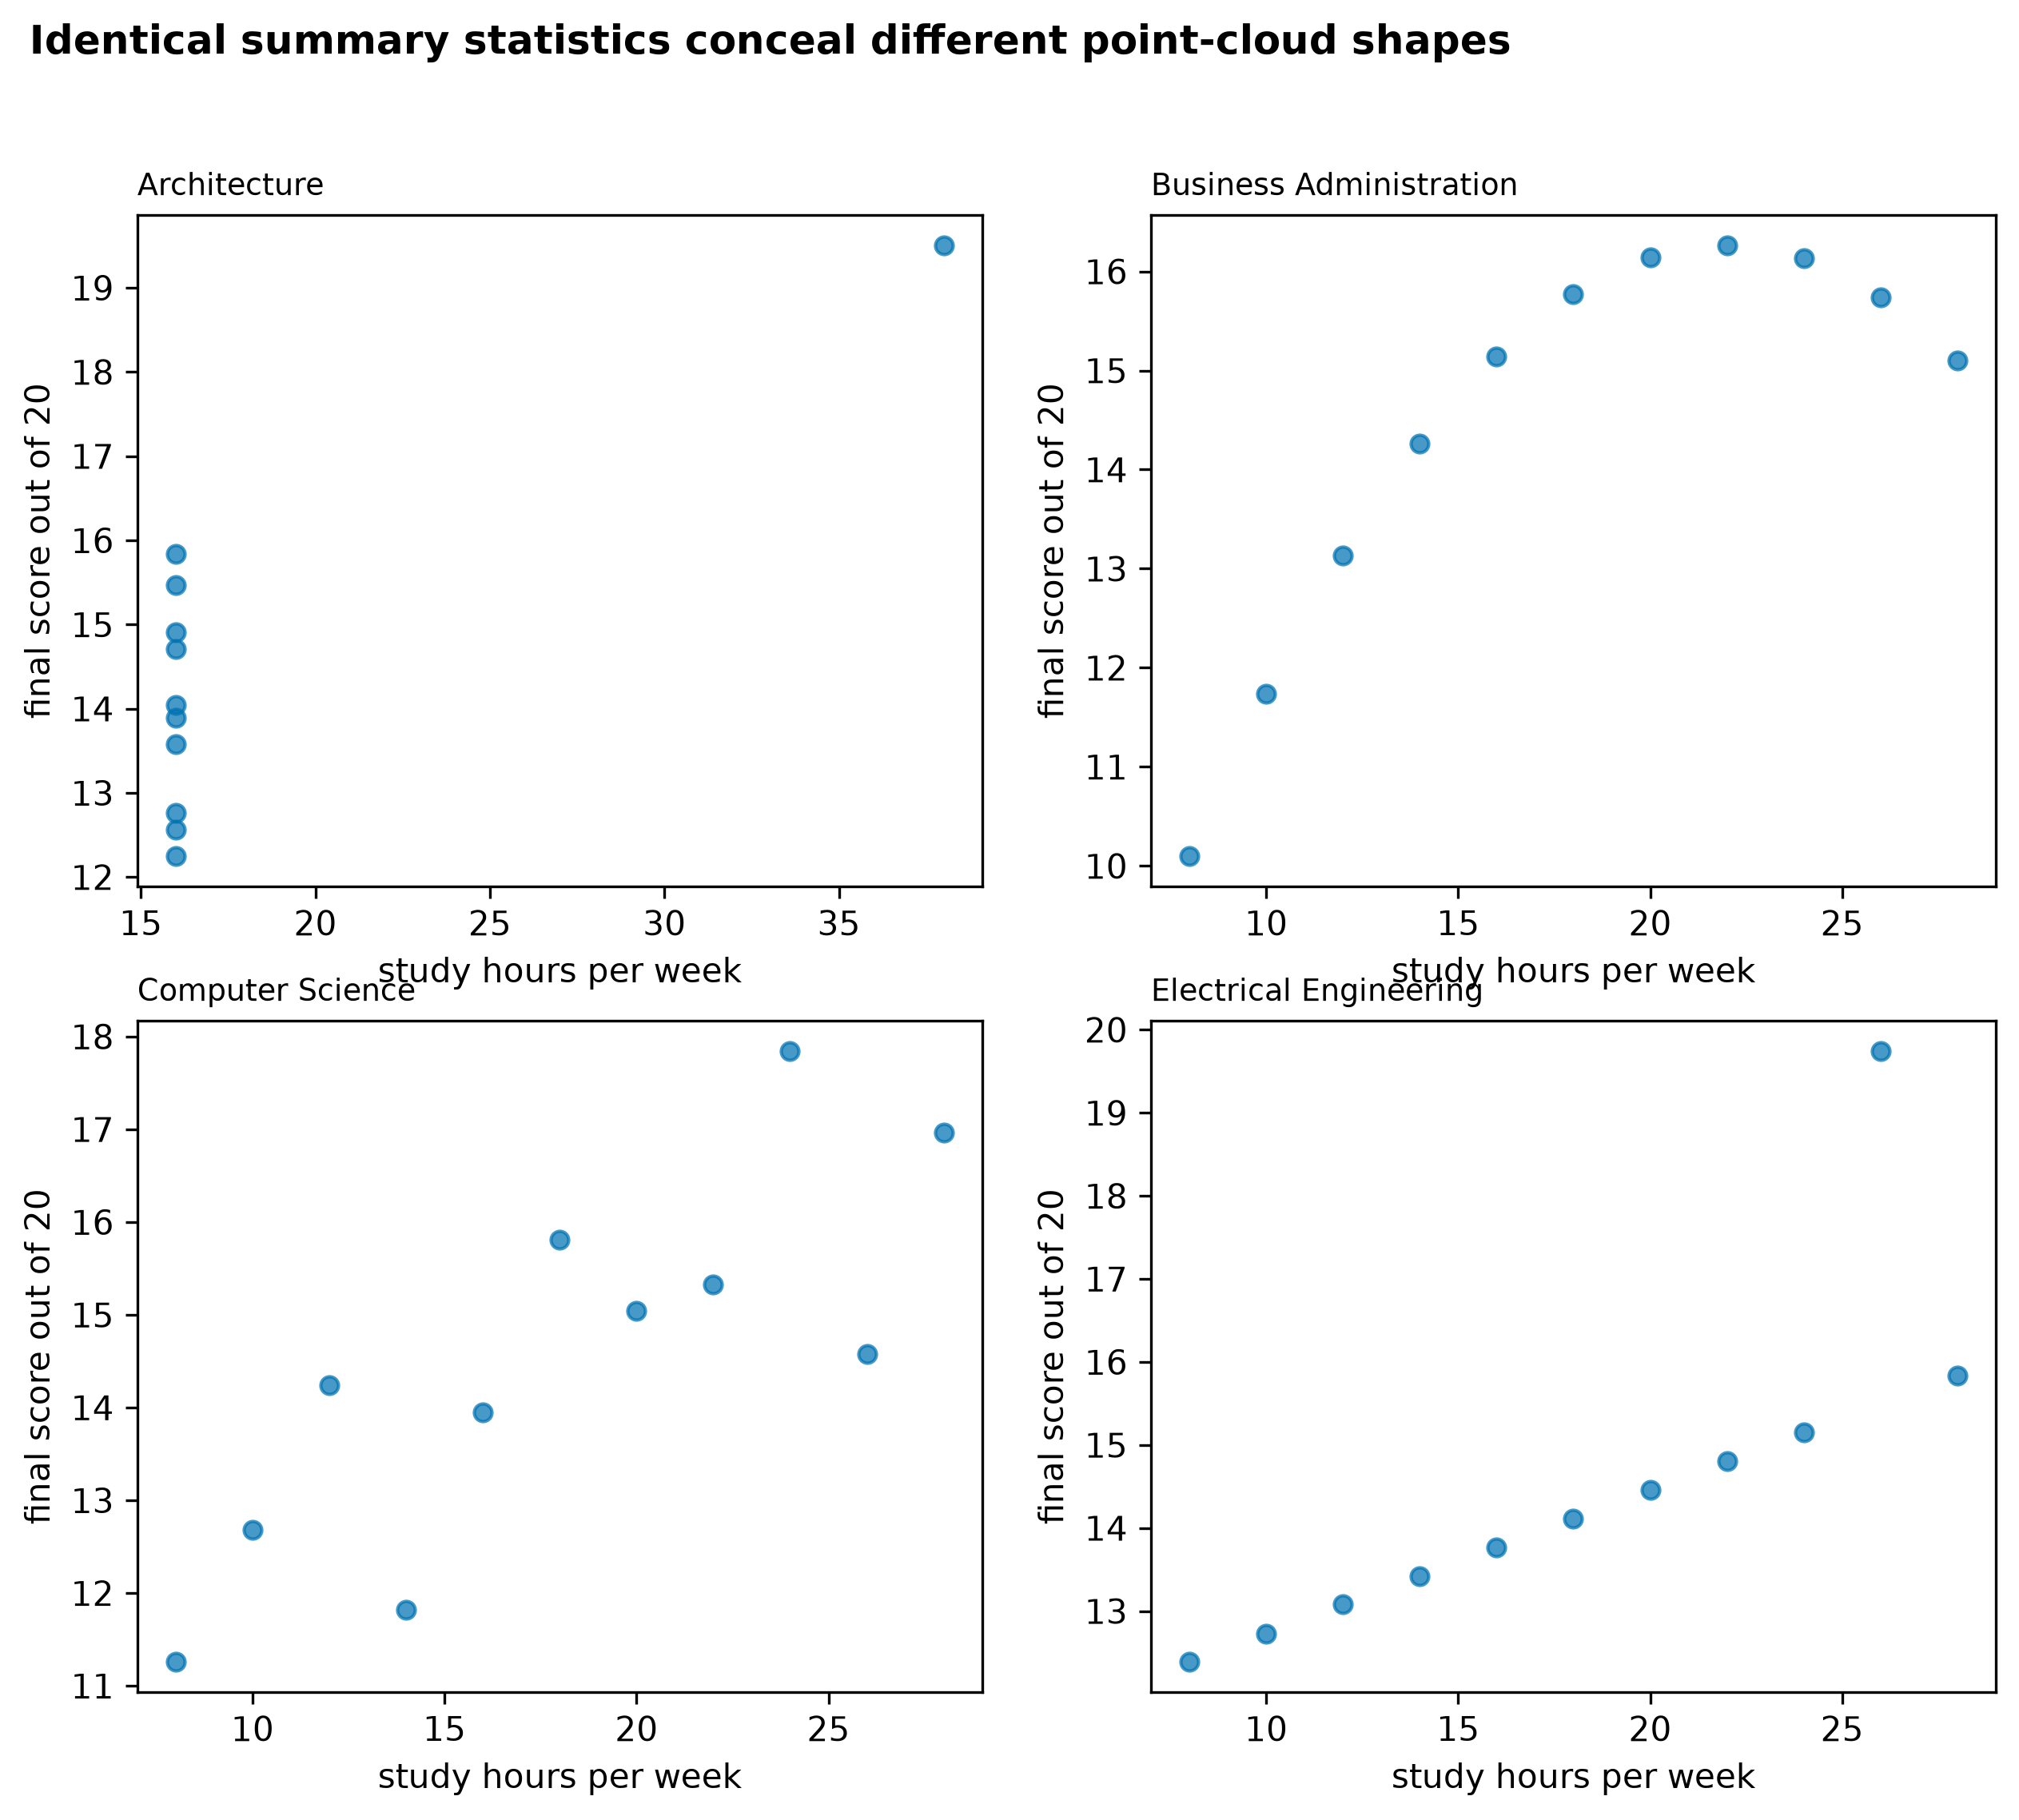

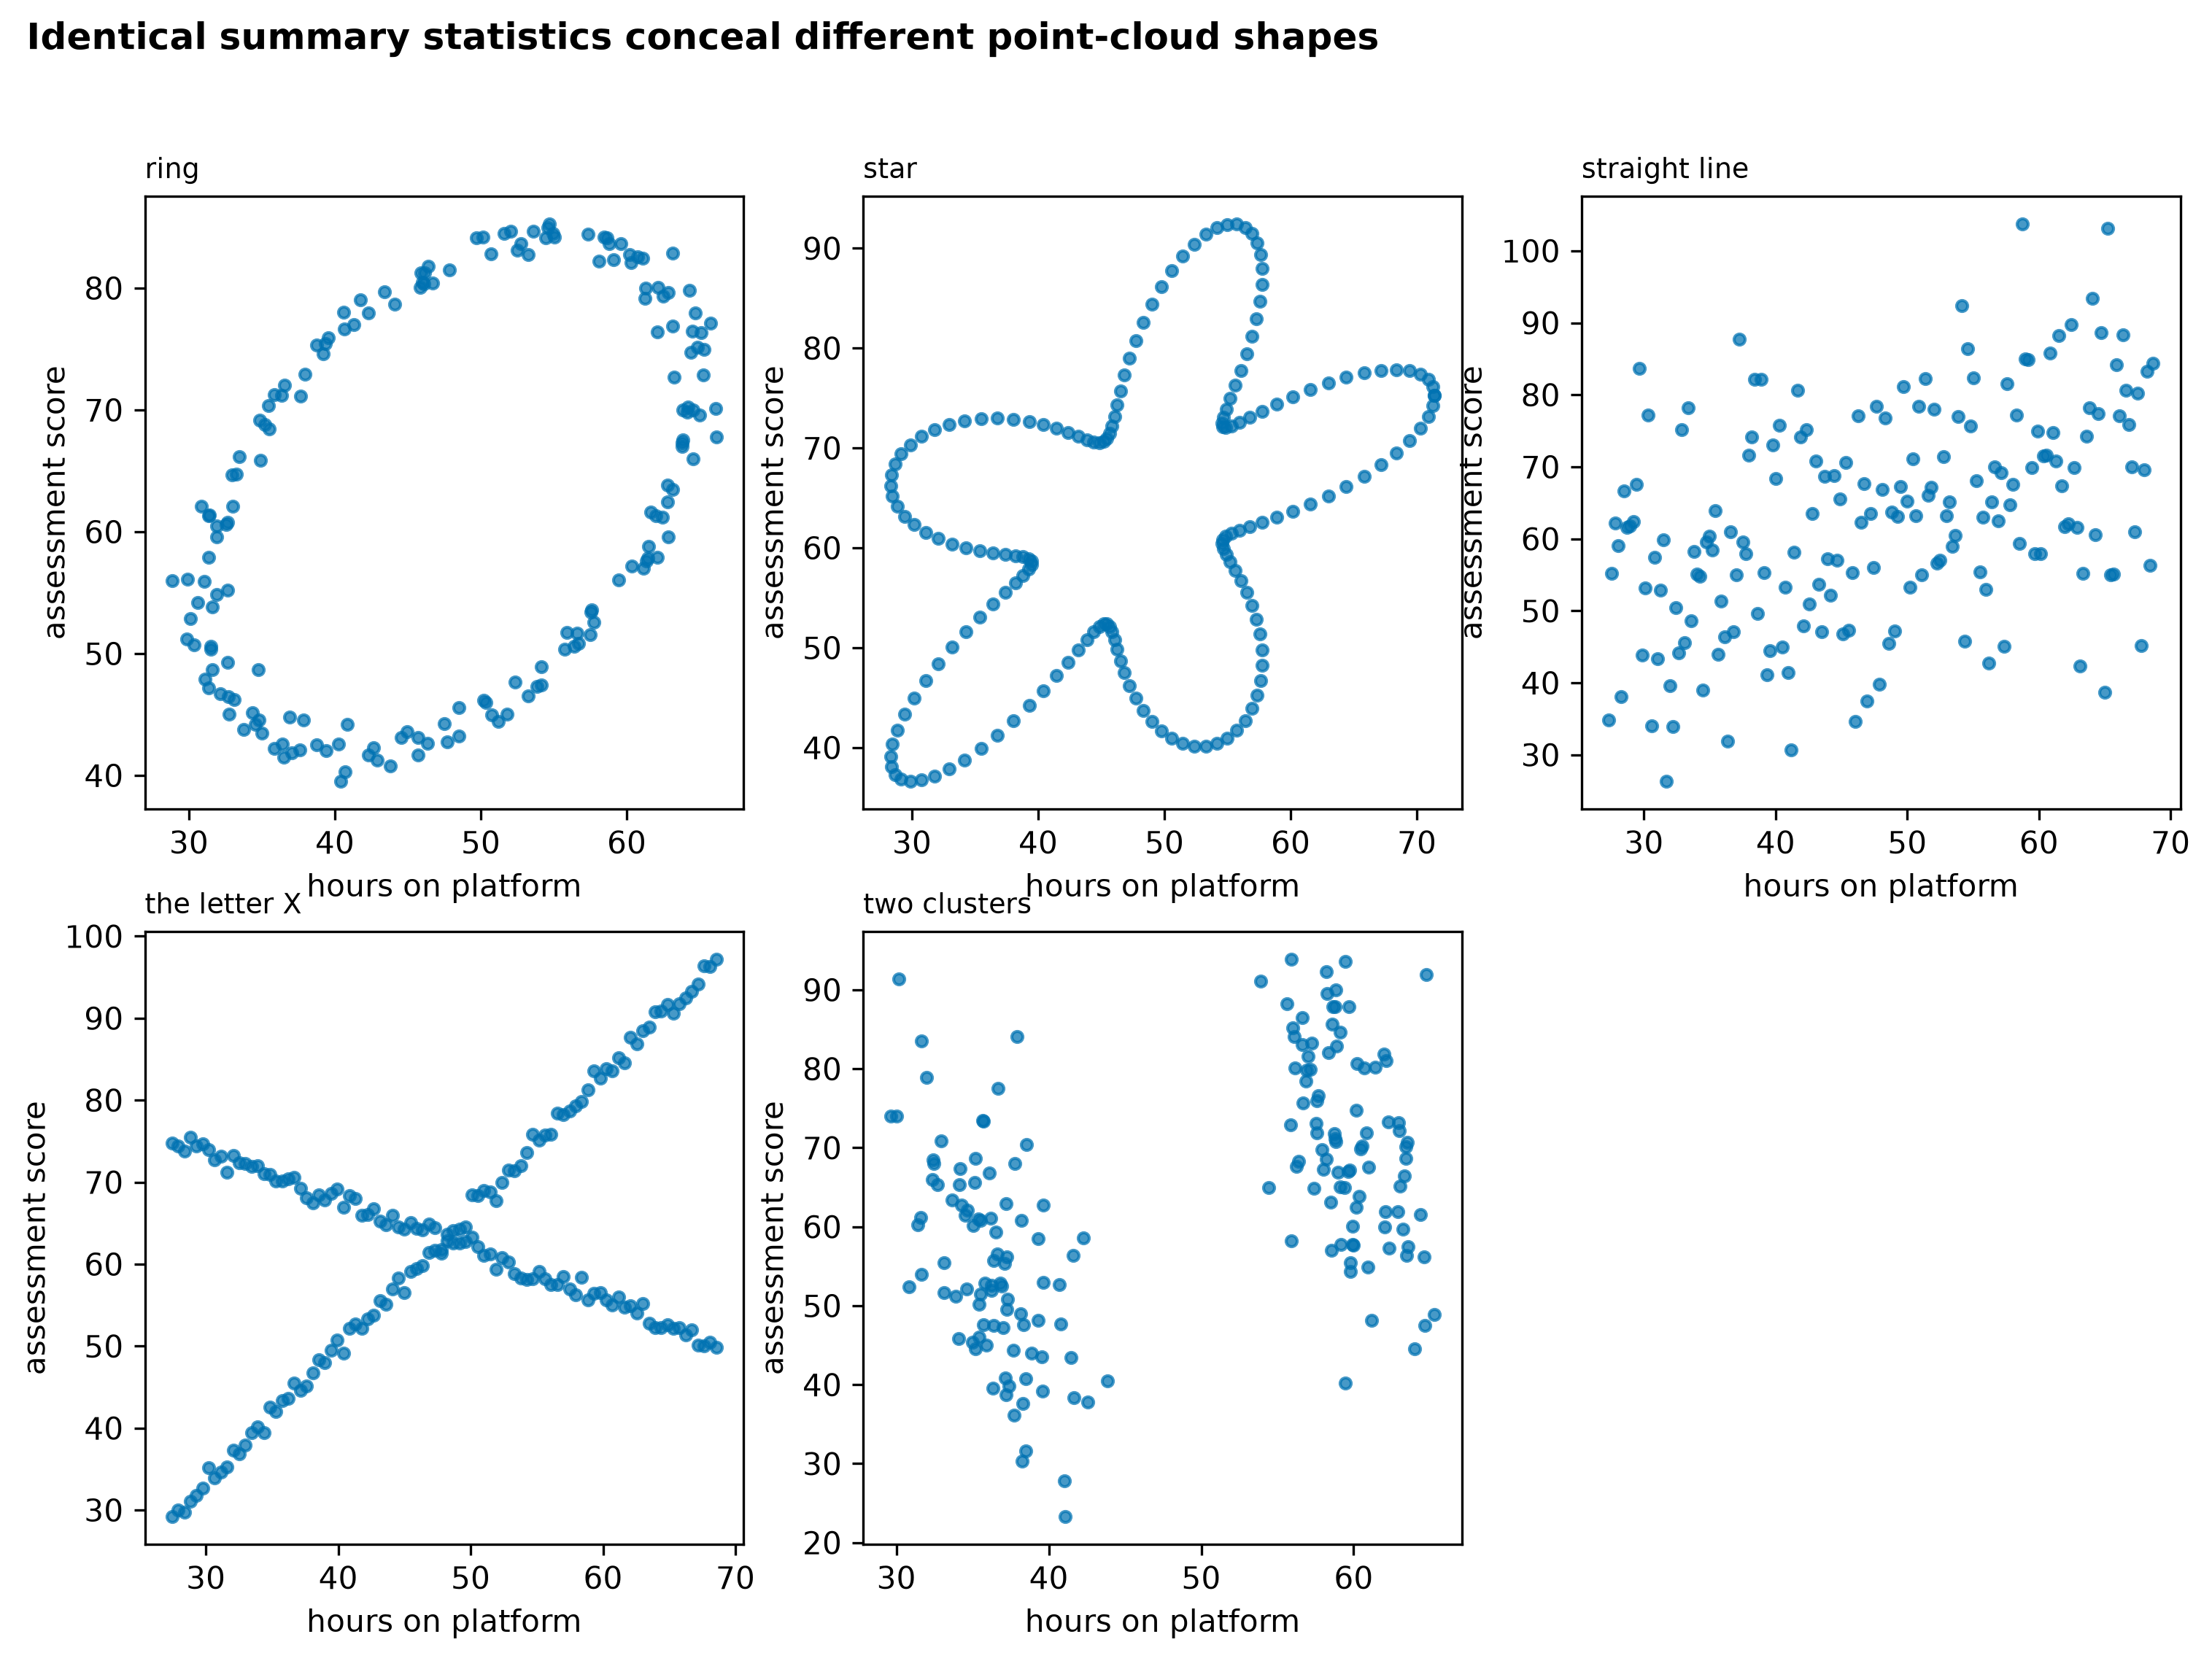

In [2]:
week3_partA.run()
display(pd.read_csv(chart_dir / 'week3_partA_diagnoses.csv'))
display(pd.read_csv(chart_dir / 'week3_case04_statistics.csv'))
display(pd.read_csv(chart_dir / 'week3_case05_statistics.csv'))
for filename in [f'week3_case{i:02d}_rebuild.png' for i in [1,2,3,6,7,8,9]] + [f'week3_case{i:02d}_redesign.png' for i in [1,2,3,6,7,8,9]] + ['week3_case04_shape_diagnostic.png','week3_case05_shape_diagnostic.png']:
    display(Image(filename=str(chart_dir / filename)))

## Part B ? Lie Factor

A?E are computed via `vizlib.lie_factor()`. C is the only honest chart; B and E require area dimension 2. Chart F has no valid Lie Factor because its two y-axes use unrelated scales. Actual revenue exceeds cost in all six months; margins rise from PKR 8m to PKR 25m.

In [3]:
week3_partBC.part_b()
display(pd.read_csv(chart_dir / 'week3_partB_lie_factor.csv'))

chart_id  data_effect  graphic_effect  lie_factor            verdict
       A        0.067           5.000       75.00 exaggerates 75.00x
       B        0.500           1.250        2.50  exaggerates 2.50x
       C        0.200           0.200        1.00             honest
       D        0.500           0.125        0.25 understates (0.25)
       E        3.000          15.000        5.00  exaggerates 5.00x
Chart F: no comparable Lie Factor; margins: [8, 12, 14, 17, 20, 25]


,chart_id,subject,ink_dimension,data_effect,graphic_effect,lie_factor,verdict,encoding
0,A,Corporate tax rate,1,0.066667,5.000,75.00,exaggerates 75.00x,"Bars drawn from a 29.6% baseline, so only the ..."
1,B,Federal health budget (Rs bn),2,0.500000,1.250,2.50,exaggerates 2.50x,A coin icon scaled 1.5x in BOTH height and width
2,C,Export earnings ($ bn),1,0.200000,0.200,1.00,honest,Bars from zero: 5.0 cm then 6.0 cm
3,D,Air-pollution index,1,0.500000,0.125,0.25,understates (0.25),Bars drawn 8.0 cm then 9.0 cm tall
4,E,City population (millions),2,3.000000,15.000,5.00,exaggerates 5.00x,A bubble whose RADIUS was set proportional to ...


## Part C ? palette evidence

The official toolkit simulates deutan, protan and tritan deficiencies and reports the worst ?E pair in each palette. The fourth course hue has a reduced CVD/contrast margin, so use direct labels or a table. Beyond three categories, prefer direct labels, marker/line styles or small multiples rather than another color.

                  palette cvd_type  slot_i  slot_j color_i color_j  delta_e
             tab10_first4   normal       2       4 #ff7f0e #d62728    18.60
             tab10_first4   deutan       3       4 #2ca02c #d62728     4.06
             tab10_first4   protan       2       3 #ff7f0e #2ca02c     0.68
             tab10_first4   tritan       1       3 #1f77b4 #2ca02c     6.72
course_series_plus_fourth   normal       2       4 #D55E00 #CC79A7    16.42
course_series_plus_fourth   deutan       3       4 #009E73 #CC79A7     7.55
course_series_plus_fourth   protan       1       4 #0072B2 #CC79A7     9.49
course_series_plus_fourth   tritan       1       3 #0072B2 #009E73     8.37


,palette,cvd_type,slot_i,slot_j,color_i,color_j,delta_e
0,tab10_first4,normal,2,4,#ff7f0e,#d62728,18.597645
1,tab10_first4,deutan,3,4,#2ca02c,#d62728,4.058730
2,tab10_first4,protan,2,3,#ff7f0e,#2ca02c,0.681177
3,tab10_first4,tritan,1,3,#1f77b4,#2ca02c,6.721180
4,course_series_plus_fourth,normal,2,4,#D55E00,#CC79A7,16.419658
5,course_series_plus_fourth,deutan,3,4,#009E73,#CC79A7,7.546638
6,course_series_plus_fourth,protan,1,4,#0072B2,#CC79A7,9.494498
7,course_series_plus_fourth,tritan,1,3,#0072B2,#009E73,8.372201


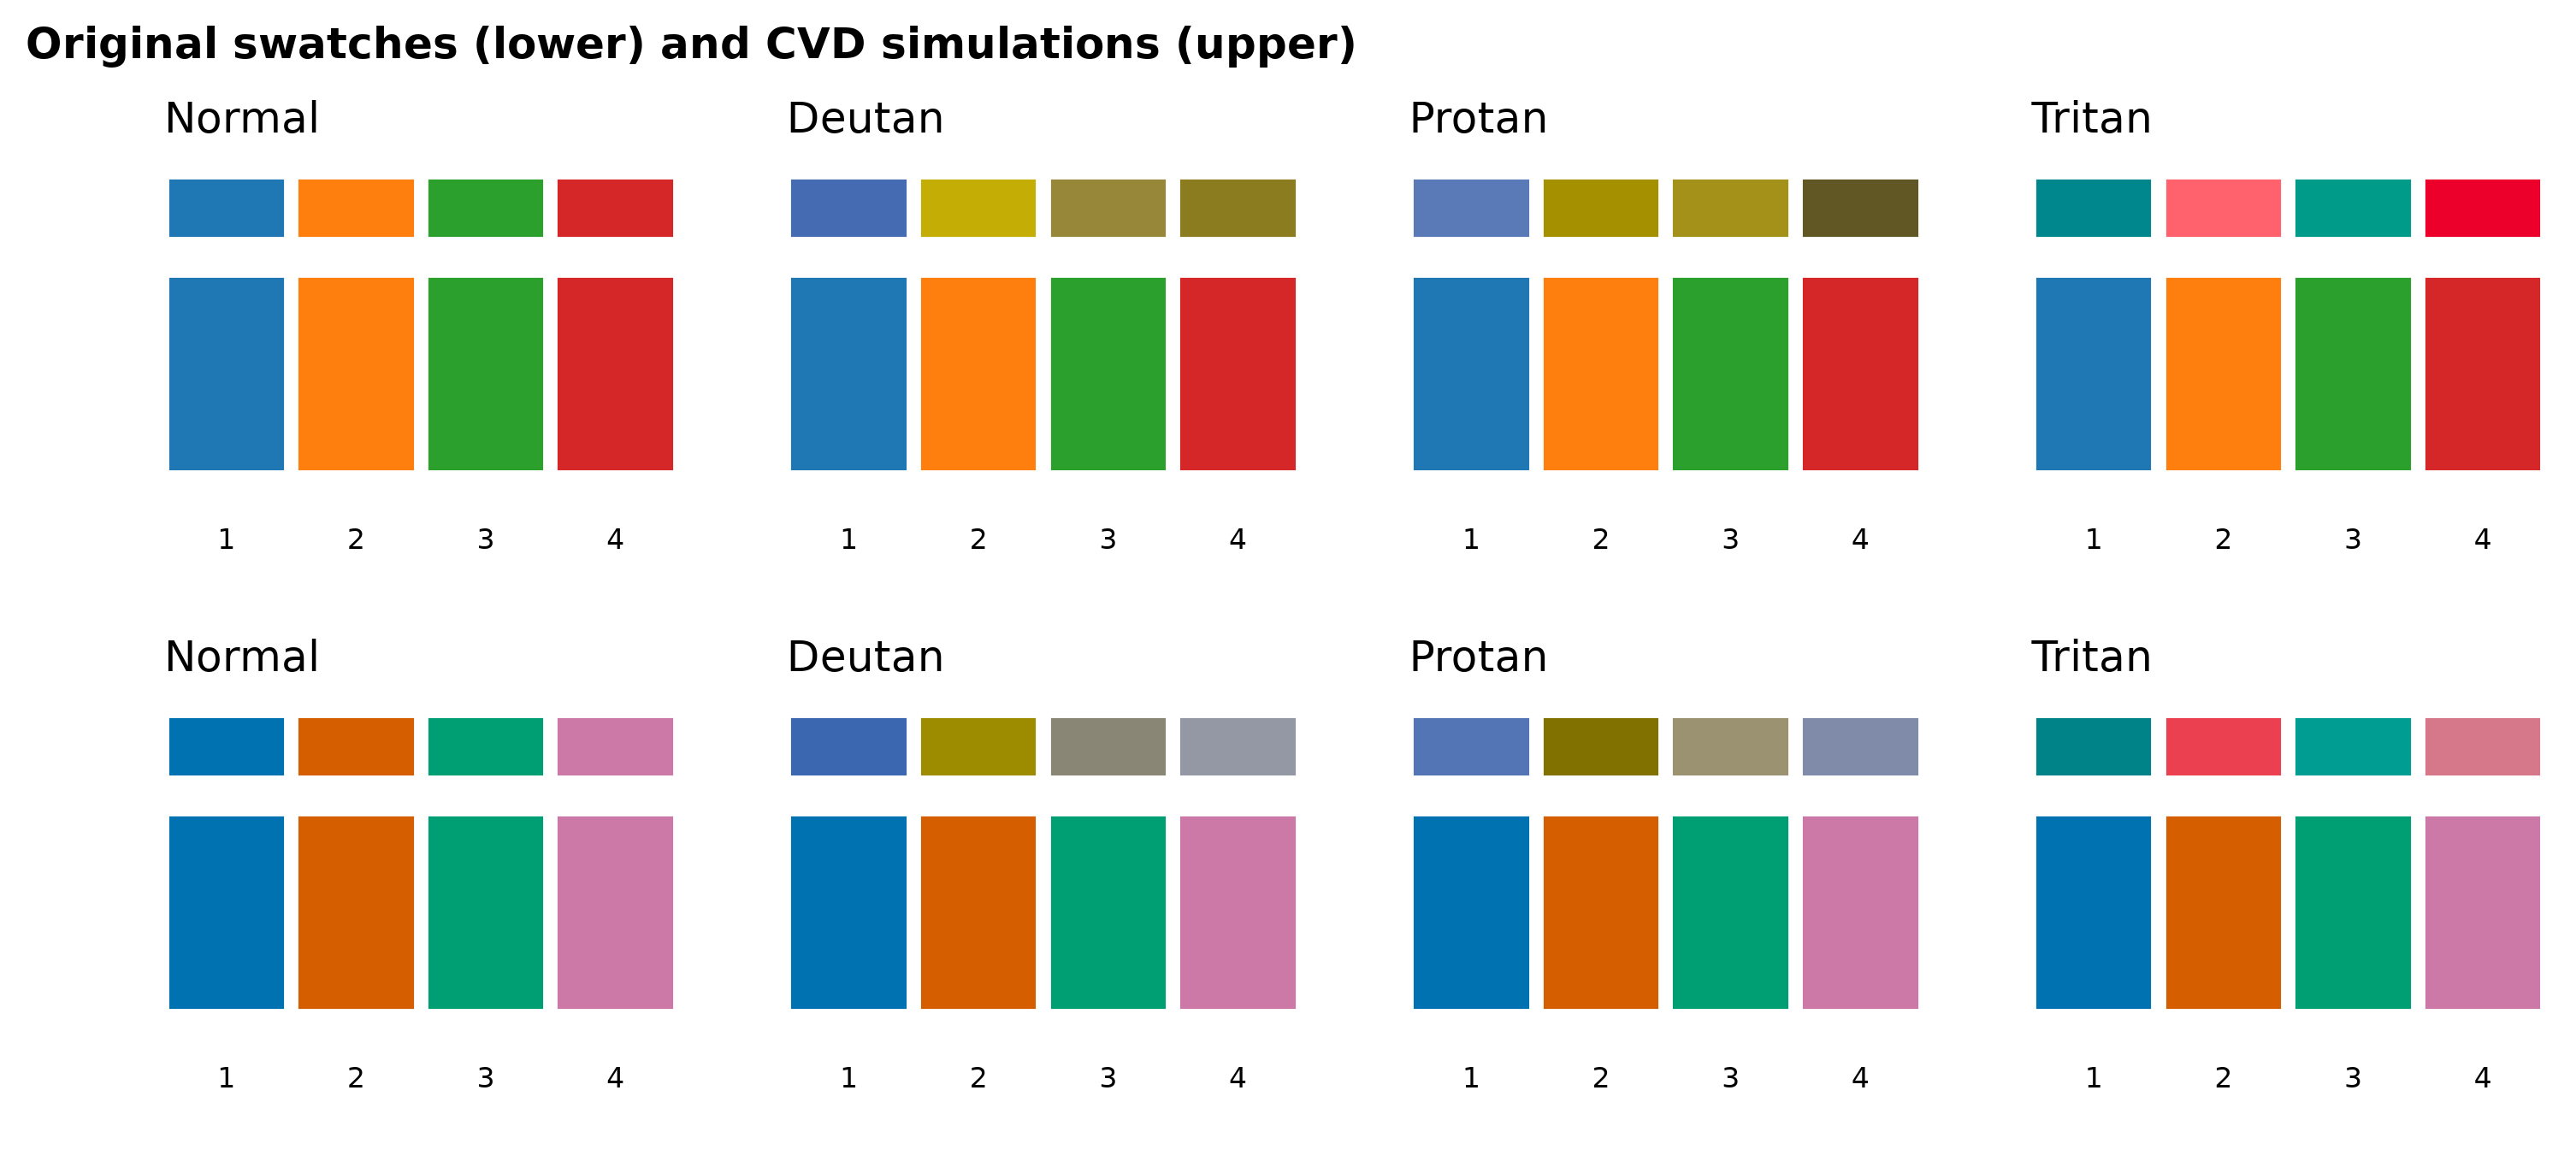

In [4]:
week3_partBC.part_c()
display(pd.read_csv(chart_dir / 'week3_partC_palette_audit.csv'))
display(Image(filename=str(chart_dir / 'week3_partC_palette.png')))

## Part D ? clinical review figure

The script runs the required inspections in order, parses three date formats, normalizes ward aliases, marks BMI 0/999 sentinels missing, excludes 29 heart-rate records above 250 bpm and eight zero readings from the HR distribution, and retains the unfiltered appendix. MAP is arithmetic-derived and excluded from the correlation matrix. The 2?2 figure is saved at 300 dpi before display.

1. df.info()
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 16 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   patient_id      10000 non-null  str    
 1   admit_date      10000 non-null  str    
 2   ward            10000 non-null  str    
 3   age             10000 non-null  int64  
 4   sex             10000 non-null  str    
 5   systolic        10000 non-null  int64  
 6   diastolic       10000 non-null  int64  
 7   map_mmhg        10000 non-null  float64
 8   heart_rate      10000 non-null  int64  
 9   spo2            10000 non-null  int64  
 10  bmi             10000 non-null  float64
 11  chol_mmol_l     10000 non-null  float64
 12  glucose_mmol_l  10000 non-null  float64
 13  los_days        10000 non-null  float64
 14  readmitted_30d  10000 non-null  int64  
 15  risk_score      10000 non-null  float64
dtypes: float64(6), int64(6), str(4)
memory usage: 1.2 MB

2. df.describe().T
  

Part D saved at 300 dpi. HR mean 78.83to78.05; >250 n=29, zero n=8; invalid BMI cells=486; all 10000 patient rows retained.


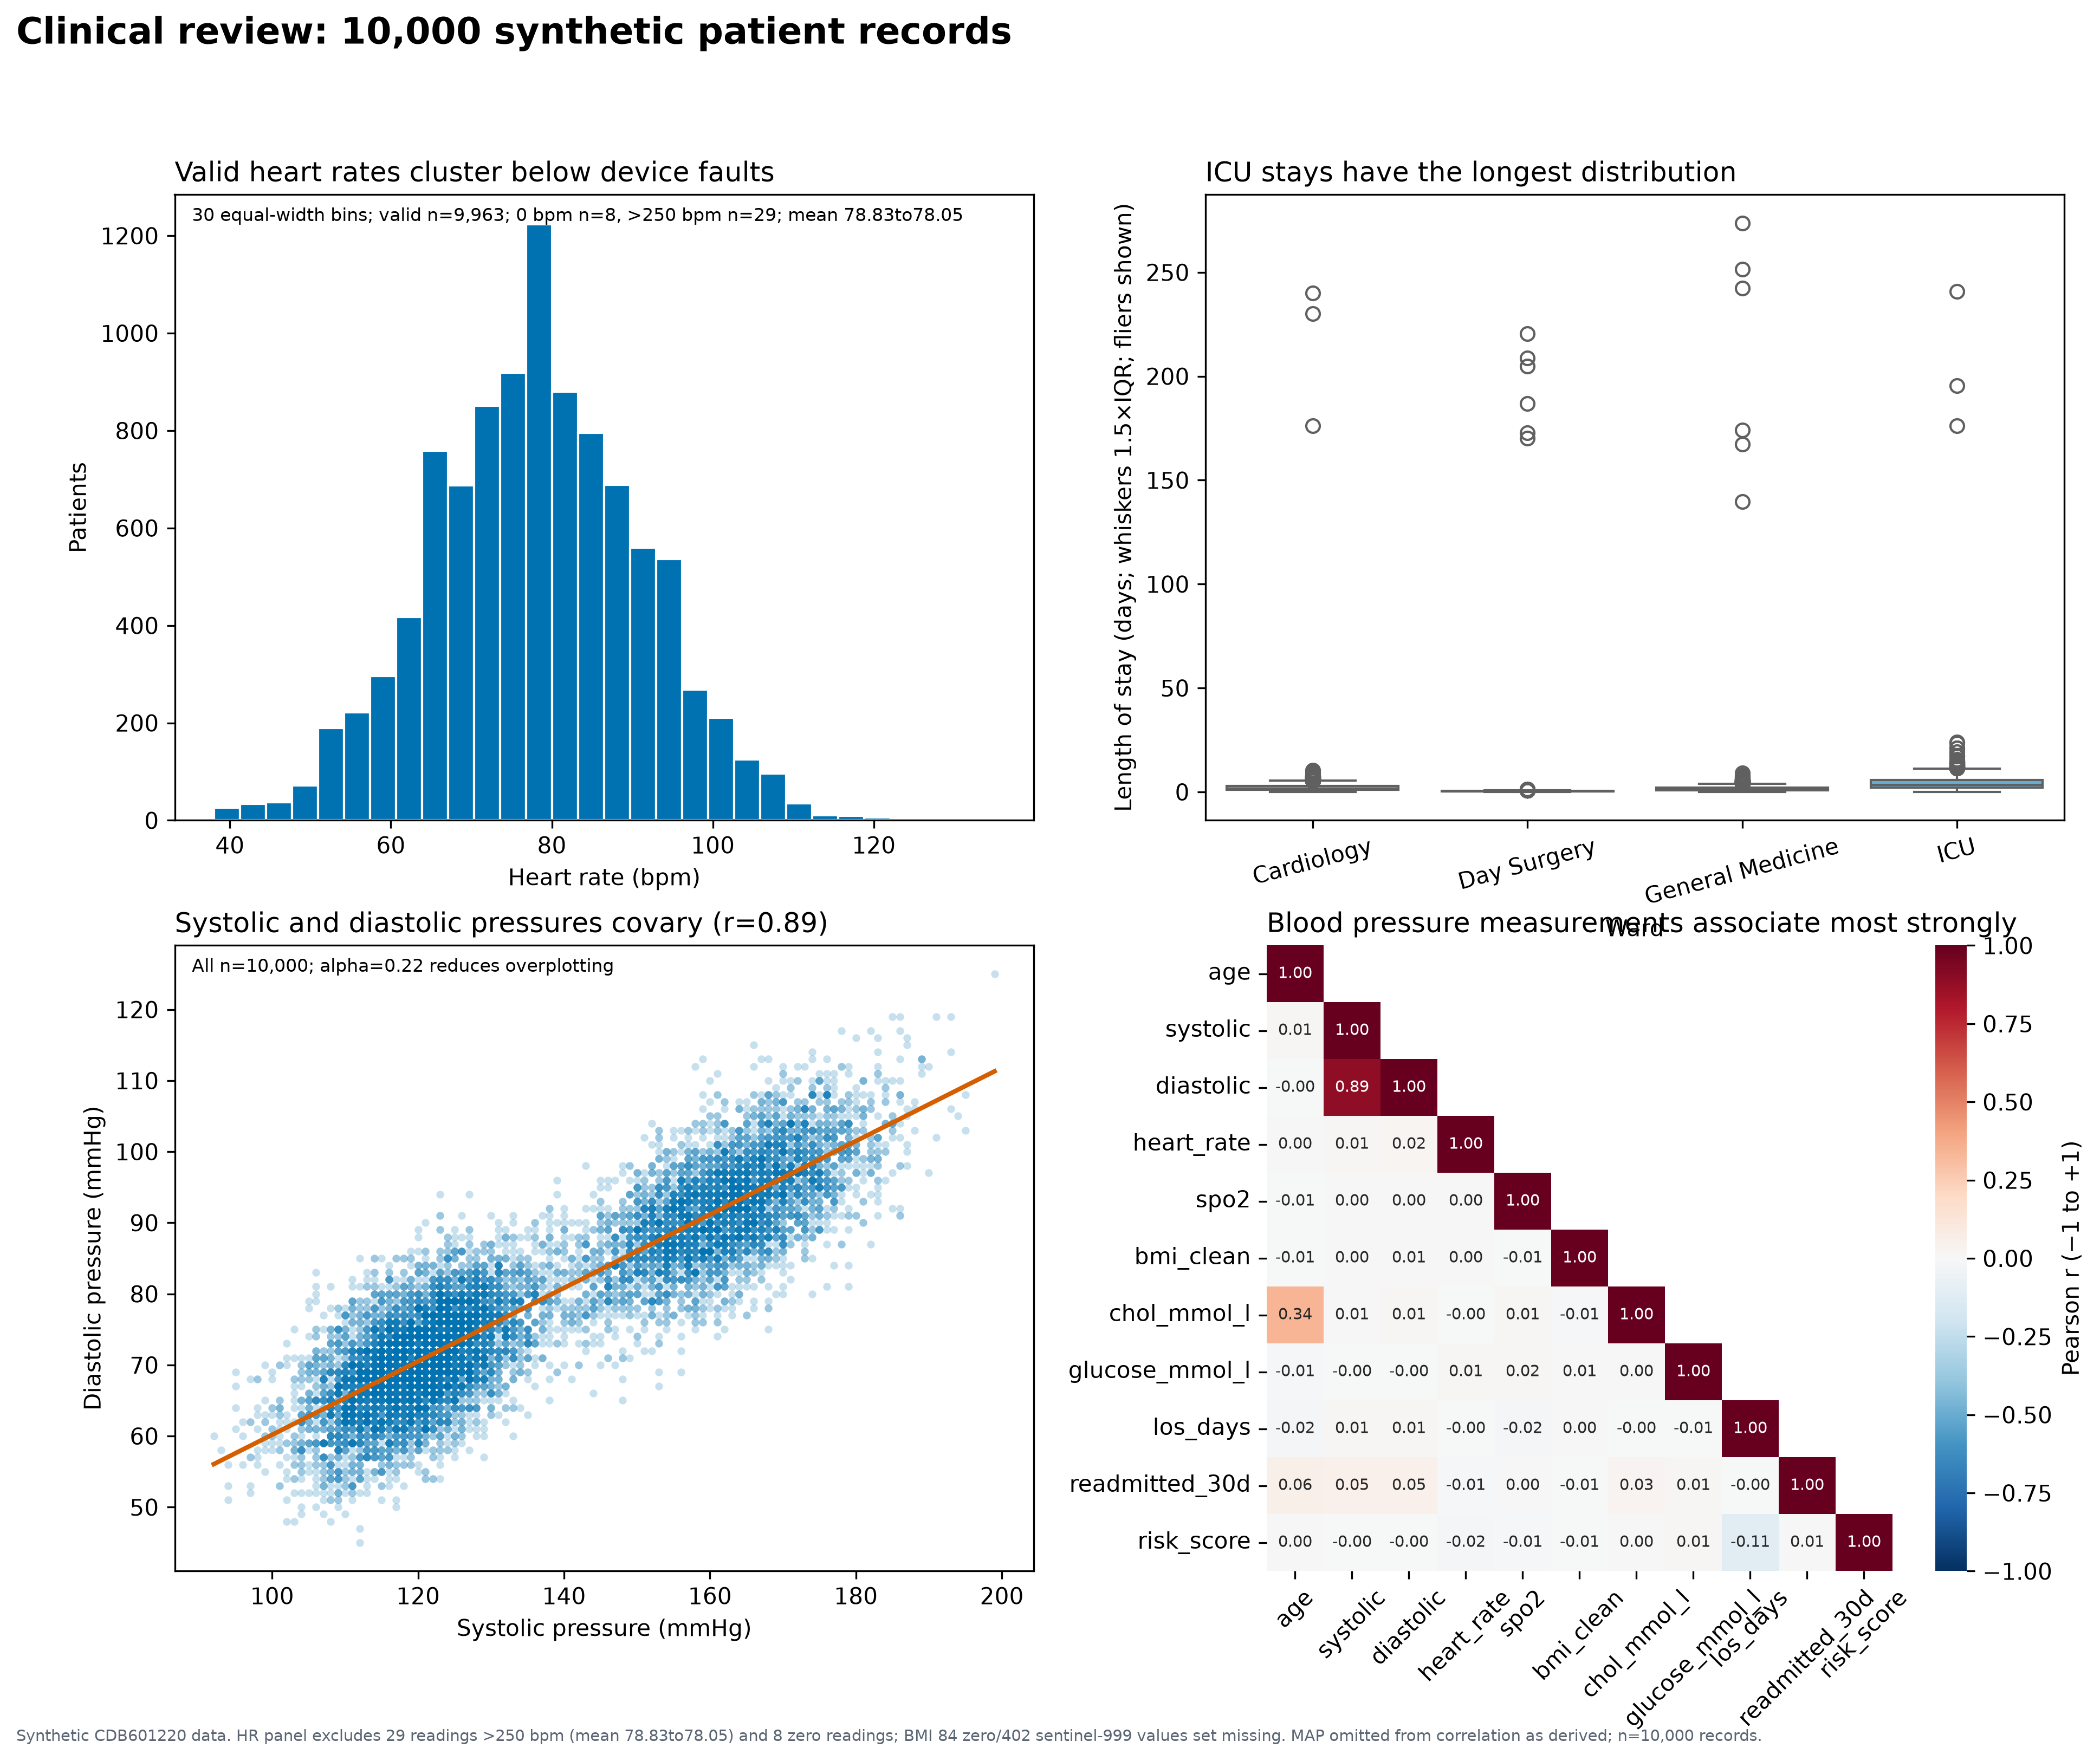

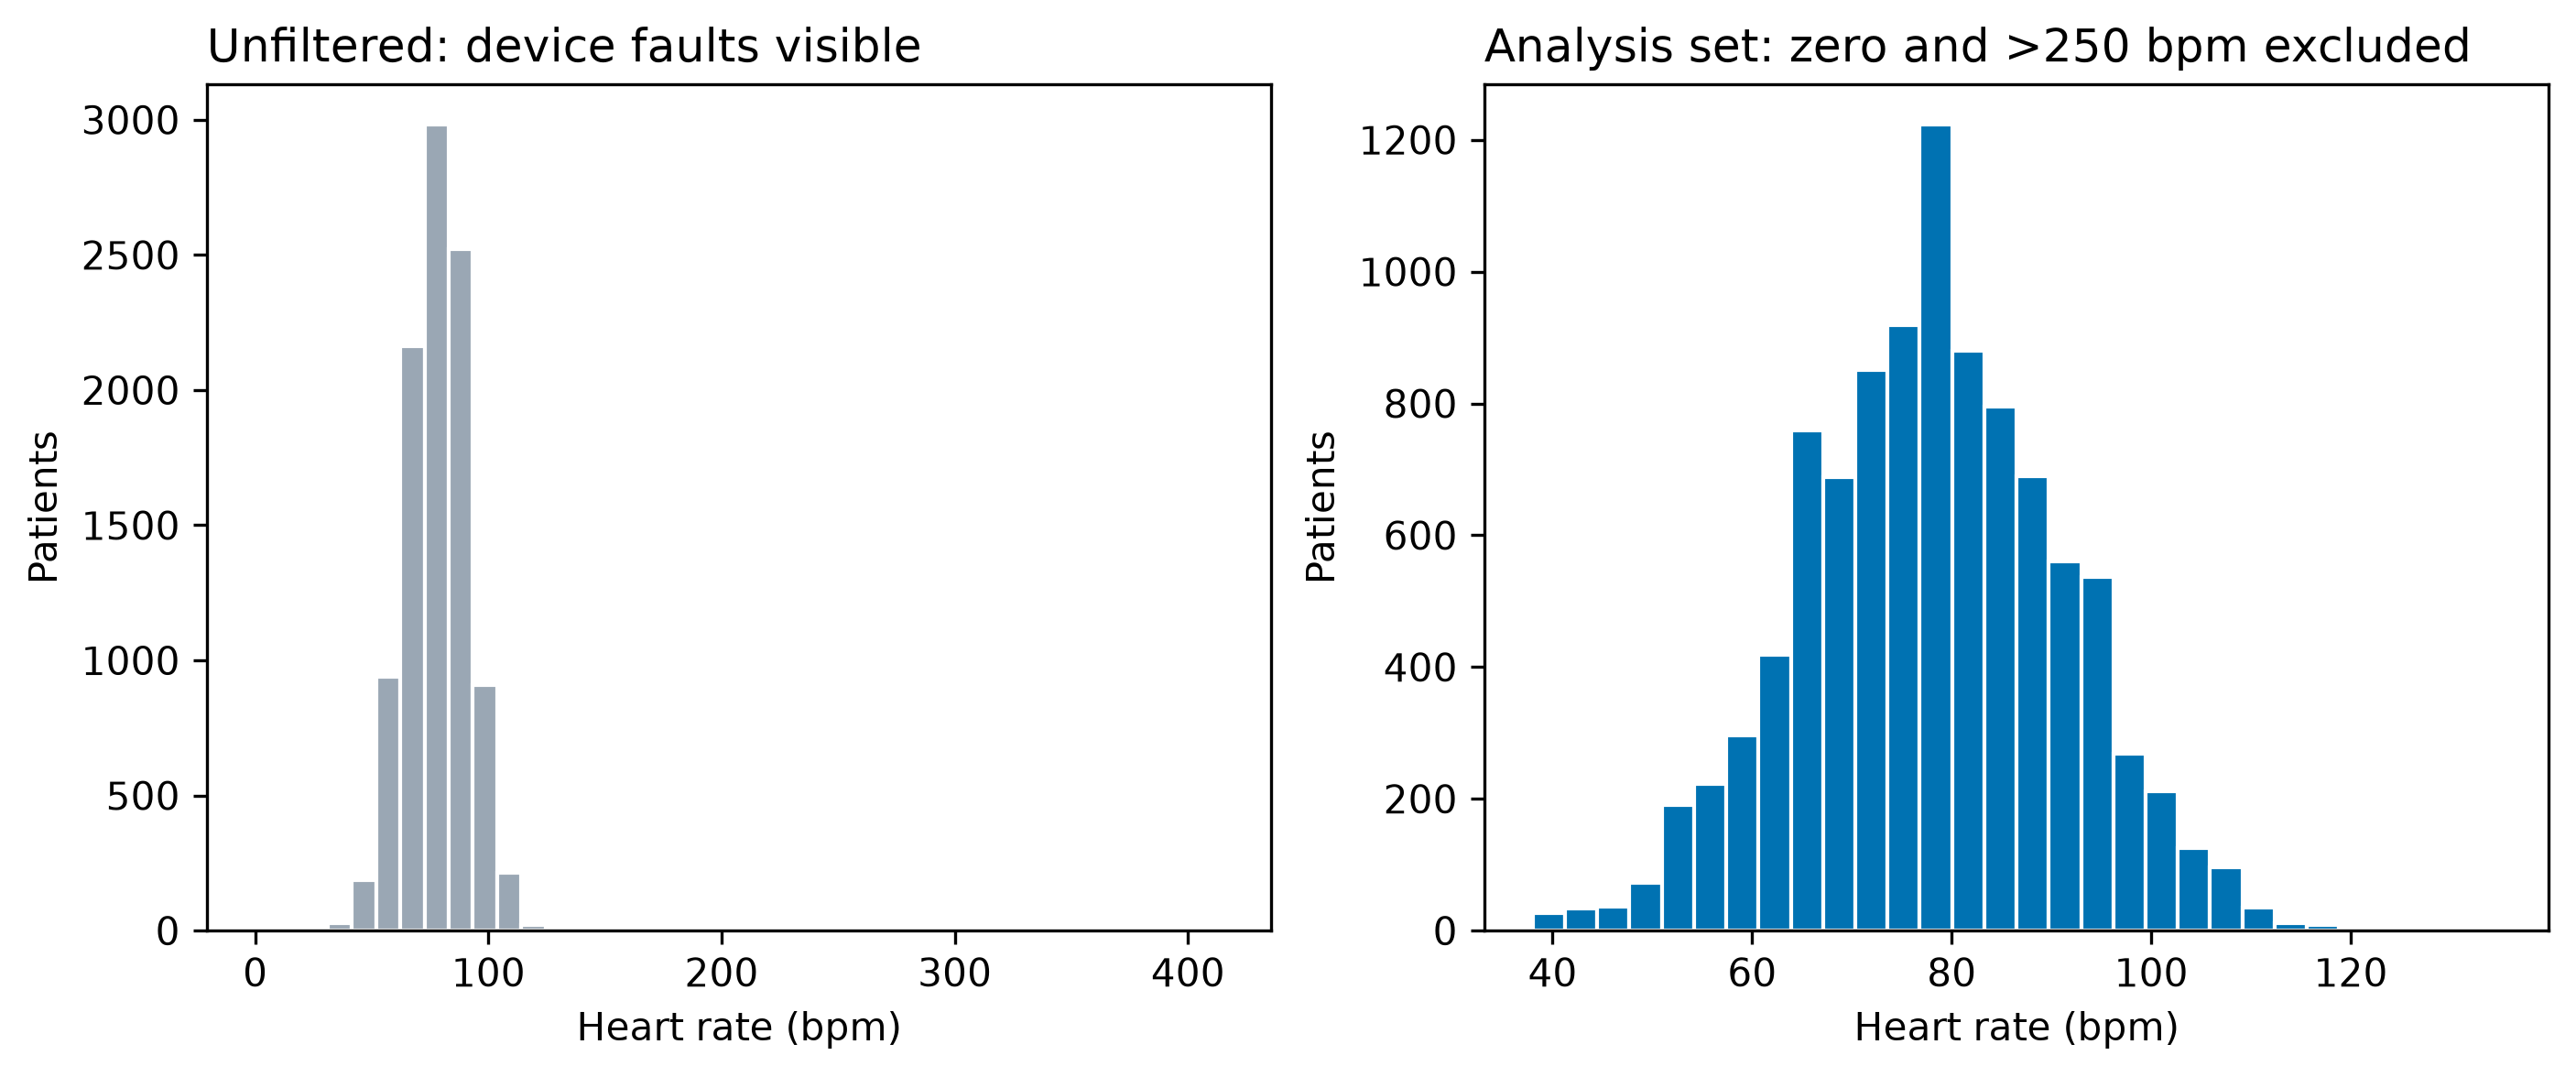

,problem,rule,affected_rows,result
0,Three date string formats,"Parse ISO, DD/MM/YYYY, and DD-Mon-YYYY explicitly",10000,All dates parsed; raw string retained
1,Ward aliases and inconsistent punctuation/case,Normalize known spellings into canonical units,6533,"['Cardiology', 'Day Surgery', 'General Medicin..."
2,BMI sentinels (0 and 999),"Set sentinels to missing, not valid measurements",486,"0=84, 999=402"
3,Heart-rate zero and >250 values,Exclude for HR distribution; display raw appendix,37,"zero=8, >250=29"
4,MAP is derived; risk_score is a ratio,Exclude derived MAP from correlation; do not a...,0,Avoid redundant BP correlation and invalid rat...


In [5]:
week3_partD.run()
display(Image(filename=str(chart_dir / 'partD_figure.png')))
display(Image(filename=str(chart_dir / 'week3_partD_heart_rate_appendix.png')))
display(pd.read_csv(chart_dir / 'week3_partD_cleaning_audit.csv'))

## Part E ? written justification

The one-page PDF and its Markdown source are generated by Part D. No clinical observations are real. No human-participant or bonus experiment results are claimed.